Descrição dos Dados

- `data_arc_en.csv` — dados dos eletrodos.
- `data_bulk_en.csv` — informações sobre o fornecimento de materiais a granel (volume).
- `data_bulk_time_en.csv` — tempos de entrega de materiais a granel.
- `data_gas_en.csv` — dados do processo de purga de gás.
- `data_temp_en.csv` — registros de medições de temperatura.
- `data_wire_en.csv` — dados sobre os materiais em arame (volume).
- `data_wire_time_en.csv` — tempos de entrega dos materiais em arame.

📌 Em todos os arquivos, a coluna **`key`** representa o **número do lote**.

É possível encontrar **múltiplas linhas com o mesmo valor em `key`**, já que cada uma corresponde a **diferentes iterações do processo de tratamento do aço**.

final_steel_en.zip

arquivos: https://coding-bootcamps.notion.site/signed/attachment%3A92df8849-9d07-4fed-8d0b-a38d9c22baf2%3Afinal_steel_en.zip?table=block&id=3b16ed1e-fc93-8054-a314-f745738a6204&spaceId=662b586e-86b7-4f44-9740-1dc06c7a67a4&name=final_steel_en.zip&cache=v2&imgBuildSrc=downloadUrlActions

## Carregamento de Dados

In [1]:
import pandas as pd
from pathlib import Path

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.model_selection import GroupKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from matplotlib import pyplot as plt

import seaborn as sns

import numpy as np

import time

# Pasta onde os dados estão localizados
# Essa variável facilita o transporte desse notebook entre meu ambiente local e o
# ambiente do bootcamp
data_location = Path("../../data/final_steel_en/")

random_state=12345

In [2]:
## helper function -> snake_case
# Essa função ajuda na padronização dos nomes de colunas para o formato snake_case
def snake_case_columns(df:pd.DataFrame):
    df.columns = (
        df.columns.str.lower()
        .str.strip()
        .str.replace("-","_")
        .str.replace(" ","_")
    )
    return df

## helper function
# Transforma os datasets em um único dataset de formato long
def build_long_dataset(arc, bulk_time, wire_time, temp):
    arc_long = (
        arc.drop(
            columns=[
                'active_power',
                'reactive_power',
                'arc_heating_interval'
            ]
        )
        .melt(
            id_vars=['key', 'heating_cycle_no'],
            var_name='variable',
            value_name='timestamp'
        )
    )

    bulk_long = (
        bulk_time.melt(
            id_vars='key',
            var_name='variable',
            value_name='timestamp'
        )
        .dropna(subset=['timestamp'])
    )

    wire_long = (
        wire_time.melt(
            id_vars='key',
            var_name='variable',
            value_name='timestamp'
        )
        .dropna(subset=['timestamp'])
    )

    temp_long = temp.rename(
        columns={'sampling_time': 'timestamp'}
    ).copy()

    temp_long['variable'] = 'sampling'

    temp_long = temp_long[
        ['key', 'variable', 'timestamp', 'temperature']
    ]

    return (
        pd.concat(
            [arc_long, bulk_long, wire_long, temp_long],
            ignore_index=True
        )
        .sort_values(['key', 'timestamp'], kind='stable')
        .reset_index(drop=True)
    )

In [3]:
# Dados dos Eletrodos
data_arc_en_raw = pd.read_csv(data_location / "data_arc_en.csv",parse_dates=["Arc heating start", 'Arc heating end'])
data_arc_en = data_arc_en_raw.copy()
data_arc_en = snake_case_columns(data_arc_en)

#
data_bulk_en_raw = pd.read_csv(data_location / "data_bulk_en.csv")
data_bulk_en = data_bulk_en_raw.copy()
data_bulk_en = snake_case_columns(data_bulk_en)

data_bulk_time_en_raw = pd.read_csv(data_location / "data_bulk_time_en.csv",parse_dates=[x for x in range(1,16,1)])
data_bulk_time_en = data_bulk_time_en_raw.copy()
data_bulk_time_en = snake_case_columns(data_bulk_time_en)

data_gas_en_raw = pd.read_csv(data_location / "data_gas_en.csv")
data_gas_en = data_gas_en_raw.copy()
data_gas_en = snake_case_columns(data_gas_en)

data_temp_en_raw = pd.read_csv(data_location / "data_temp_en.csv", parse_dates=['Sampling time'])
data_temp_en = data_temp_en_raw.copy()
data_temp_en = snake_case_columns(data_temp_en)

data_wire_en_raw = pd.read_csv(data_location / "data_wire_en.csv")
data_wire_en = data_wire_en_raw.copy()
data_wire_en = snake_case_columns(data_wire_en)

data_wire_time_en_raw = pd.read_csv(data_location / "data_wire_time_en.csv", parse_dates=[x for x in range(1,10,1)])
data_wire_time_en = data_wire_time_en_raw.copy()
data_wire_time_en = snake_case_columns(data_wire_time_en)

# Processamento e Limpeza de Dados

Para facilitar nossas análises seguintes, vamos criar algumas colunas e novos datasets em formato **long**

In [4]:
## Coluna representando duração de cada ciclo de aquecimento
data_arc_en['arc_heating_interval'] = (data_arc_en['arc_heating_end'] - data_arc_en['arc_heating_start']).dt.total_seconds()

# Aqui vamos criar uma chave para o ciclo de aquecimento dentro de cada Lote de Refino
# Secundário. Dessa forma podemos identificar não somente o Lote mas também o ciclo
# de aquecimento

data_arc_en = data_arc_en.sort_values(['key','arc_heating_start'])
data_arc_en['heating_cycle_no'] = data_arc_en.groupby('key').cumcount() + 1

In [5]:
## Criando identificador para cada medição de temperatura unívoca

data_temp_en = data_temp_en.sort_values(by=['key','sampling_time']).copy()
data_temp_en['sampling_no'] = data_temp_en.groupby('key').cumcount() + 1

In [6]:
data_long = build_long_dataset(
    data_arc_en,
    data_bulk_time_en,
    data_wire_time_en,
    data_temp_en
)

## Valores Ausentes

### Dados dos Eletrodos

In [7]:
data_arc_en.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 14876 entries, 0 to 14875
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   key                   14876 non-null  int64         
 1   arc_heating_start     14876 non-null  datetime64[ns]
 2   arc_heating_end       14876 non-null  datetime64[ns]
 3   active_power          14876 non-null  float64       
 4   reactive_power        14876 non-null  float64       
 5   arc_heating_interval  14876 non-null  float64       
 6   heating_cycle_no      14876 non-null  int64         
dtypes: datetime64[ns](2), float64(3), int64(2)
memory usage: 929.8 KB


### Dados dos Materiais a Granel (Volume)

In [8]:
data_bulk_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   key      3129 non-null   int64  
 1   bulk_1   252 non-null    float64
 2   bulk_2   22 non-null     float64
 3   bulk_3   1298 non-null   float64
 4   bulk_4   1014 non-null   float64
 5   bulk_5   77 non-null     float64
 6   bulk_6   576 non-null    float64
 7   bulk_7   25 non-null     float64
 8   bulk_8   1 non-null      float64
 9   bulk_9   19 non-null     float64
 10  bulk_10  176 non-null    float64
 11  bulk_11  177 non-null    float64
 12  bulk_12  2450 non-null   float64
 13  bulk_13  18 non-null     float64
 14  bulk_14  2806 non-null   float64
 15  bulk_15  2248 non-null   float64
dtypes: float64(15), int64(1)
memory usage: 391.2 KB


In [9]:
data_bulk_time_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   key      3129 non-null   int64         
 1   bulk_1   252 non-null    datetime64[ns]
 2   bulk_2   22 non-null     datetime64[ns]
 3   bulk_3   1298 non-null   datetime64[ns]
 4   bulk_4   1014 non-null   datetime64[ns]
 5   bulk_5   77 non-null     datetime64[ns]
 6   bulk_6   576 non-null    datetime64[ns]
 7   bulk_7   25 non-null     datetime64[ns]
 8   bulk_8   1 non-null      datetime64[ns]
 9   bulk_9   19 non-null     datetime64[ns]
 10  bulk_10  176 non-null    datetime64[ns]
 11  bulk_11  177 non-null    datetime64[ns]
 12  bulk_12  2450 non-null   datetime64[ns]
 13  bulk_13  18 non-null     datetime64[ns]
 14  bulk_14  2806 non-null   datetime64[ns]
 15  bulk_15  2248 non-null   datetime64[ns]
dtypes: datetime64[ns](15), int64(1)
memory usage: 391.2 KB


Vamos verificar se todos os materiais que tem volumes válidos nos conjuntos de dados também tem valores de data-hora válidos. Em outras palavras, precisamos ter certeza de que temos dados da data-hora de adição para cada um dos materiais dos quais temos dados de adição (e vice e versa).

Também vamos verificar se todos os Lotes identificados pela coluna **key** estão representados nos conjuntos de dados **data_bulk_time_en** e **data_bulk_en**.

In [10]:
print("Número de colunas para o conjunto de dados de adições de materiais à granel:", data_bulk_en.shape[1])
print("Número de colunas para o conjunto de dados de data-hora de adições de materiais à granel:", data_bulk_time_en.shape[1])
print("Número de colunas que tem equivalência de validade de dados para os conjuntos de dados de adição de materiais à granel:",((data_bulk_time_en.isnull() == data_bulk_en.isnull()).sum() == len(data_bulk_en)).sum())

Número de colunas para o conjunto de dados de adições de materiais à granel: 16
Número de colunas para o conjunto de dados de data-hora de adições de materiais à granel: 16
Número de colunas que tem equivalência de validade de dados para os conjuntos de dados de adição de materiais à granel: 16


Como não temos divergências entre os dados de quantidades de materiais adicionados e os dados de data-hora das adições, não precisamos fazer nada sobre os valores ausentes nesses conjuntos de dados. Valores ausentes significam que os matereiais correspondentes as colunas não foram adicionados aquele Lote de Refino Secundário.

### Dados de Temperatura

In [11]:
data_temp_en.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15907 entries, 0 to 15906
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   key            15907 non-null  int64         
 1   sampling_time  15907 non-null  datetime64[ns]
 2   temperature    13006 non-null  float64       
 3   sampling_no    15907 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 621.4 KB


In [12]:
data_temp_en['sampling_time'].describe(datetime_is_numeric=True)

count                            15907
mean     2019-07-02 09:55:01.000942848
min                2019-05-03 11:16:18
25%         2019-06-01 16:24:51.500000
50%                2019-06-30 10:31:14
75%                2019-08-03 12:07:59
max                2019-09-01 04:38:08
Name: sampling_time, dtype: object

In [13]:
missing_temp = data_temp_en.loc[data_temp_en['temperature'].isnull()]

In [14]:
missing_temp['sampling_time'].describe(datetime_is_numeric=True)

count                             2901
mean     2019-08-19 02:14:00.281282304
min                2019-08-06 03:24:43
25%                2019-08-12 12:51:11
50%                2019-08-18 23:26:16
75%                2019-08-25 15:52:51
max                2019-09-01 04:38:08
Name: sampling_time, dtype: object

Parece que os valores nulos estão concentrados no final do cojunto de dados pois os mesmos começam em dia 06 de Agosto de 2019 às 03:24:43. Vamos verificar se existem valores válidos no cojunto de dados original a partir dessa data-hora ou se todos os valores a partir dessa data-hora são nulos:

In [15]:
data_temp_en.loc[data_temp_en['sampling_time'] >= "2019-08-06 03:24:43"].info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3639 entries, 12268 to 15906
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   key            3639 non-null   int64         
 1   sampling_time  3639 non-null   datetime64[ns]
 2   temperature    738 non-null    float64       
 3   sampling_no    3639 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 142.1 KB


Existem apenas 738 temperaturas válidas a partir de 2019-08-06 03:24:43, mas isso significa que nem todos os valores são nulos no final do conjunto de dados. Não parece que temos um problema mais grave no conjunto de dados, mas ainda assim precisamos remover essas temperaturas nulas. Como estamos usando temperaturas como objetivos, não podemos fazer algum tipo de imputação pois isso afetaria a confiabilidade do modelo final treinado em dados não necessariamente reais e afetados por técnicas de imputação.

In [16]:
data_temp_en = data_temp_en.dropna()

### Dados de Adição de Materiais em Arame

In [17]:
data_wire_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   key     3081 non-null   int64  
 1   wire_1  3055 non-null   float64
 2   wire_2  1079 non-null   float64
 3   wire_3  63 non-null     float64
 4   wire_4  14 non-null     float64
 5   wire_5  1 non-null      float64
 6   wire_6  73 non-null     float64
 7   wire_7  11 non-null     float64
 8   wire_8  19 non-null     float64
 9   wire_9  29 non-null     float64
dtypes: float64(9), int64(1)
memory usage: 240.8 KB


In [18]:
data_wire_time_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   key     3081 non-null   int64         
 1   wire_1  3055 non-null   datetime64[ns]
 2   wire_2  1079 non-null   datetime64[ns]
 3   wire_3  63 non-null     datetime64[ns]
 4   wire_4  14 non-null     datetime64[ns]
 5   wire_5  1 non-null      datetime64[ns]
 6   wire_6  73 non-null     datetime64[ns]
 7   wire_7  11 non-null     datetime64[ns]
 8   wire_8  19 non-null     datetime64[ns]
 9   wire_9  29 non-null     datetime64[ns]
dtypes: datetime64[ns](9), int64(1)
memory usage: 240.8 KB


Vamos verificar se todos os materiais que tem quantidades válidas nos conjuntos de dados também tem valores de data-hora válidos. Em outras palavras, precisamos ter certeza de que temos dados da data-hora de adição para cada um dos materiais dos quais temos dados de adição (e vice e versa).

Também vamos verificar se todos os Lotes identificados pela coluna **key** estão representados nos conjuntos de dados **data_wire_time_en** e **data_wire_en**.

In [19]:
print("Número de colunas para o conjunto de dados de adições de materiais à granel:", data_wire_en.shape[1])
print("Número de colunas para o conjunto de dados de data-hora de adições de materiais à granel:", data_wire_time_en.shape[1])
print("Número de colunas que tem equivalência de validade de dados para os conjuntos de dados de adição de materiais à granel:",((data_wire_time_en.isnull() == data_wire_en.isnull()).sum() == len(data_wire_en)).sum())

Número de colunas para o conjunto de dados de adições de materiais à granel: 10
Número de colunas para o conjunto de dados de data-hora de adições de materiais à granel: 10
Número de colunas que tem equivalência de validade de dados para os conjuntos de dados de adição de materiais à granel: 10


Como não temos divergências entre os dados de quantidades de materiais adicionados e os dados de data-hora das adições, não precisamos fazer nada sobre os valores ausentes nesses conjuntos de dados. Valores ausentes significam que os matereiais correspondentes as colunas não foram adicionados aquele Lote de Refino Secundário.

## Valores Extremos

### Coluna **reactive_power** dos Dados dos Eletrodos

In [20]:
data_arc_en.describe()

,key,active_power,reactive_power,arc_heating_interval,heating_cycle_no
count,14876.000000,14876.000000,14876.000000,14876.000000,14876.000000
mean,1615.220422,0.670441,0.452592,171.670946,3.093708
std,934.571502,0.408159,5.878702,98.186803,1.783121
min,1.000000,0.030002,-715.504924,11.000000,1.000000
25%,806.000000,0.395297,0.290991,107.000000,2.000000
50%,1617.000000,0.555517,0.415962,147.000000,3.000000
75%,2429.000000,0.857034,0.637371,214.000000,4.000000
max,3241.000000,3.731596,2.676388,907.000000,16.000000


In [21]:
data_arc_en.sort_values(by='reactive_power')

,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no
9780,2116,2019-07-24 00:44:48,2019-07-24 00:46:37,0.495782,-715.504924,109.0,3
5596,1216,2019-06-16 08:22:19,2019-06-16 08:22:30,0.030188,0.020806,11.0,6
2419,521,2019-05-22 17:42:57,2019-05-22 17:43:11,0.030563,0.021154,14.0,4
4914,1060,2019-06-11 04:31:57,2019-06-11 04:32:08,0.031630,0.022485,11.0,4
4633,1000,2019-06-09 01:17:44,2019-06-09 01:17:57,0.038186,0.022983,13.0,3
...,...,...,...,...,...,...,...
13760,2985,2019-08-23 19:03:07,2019-08-23 19:14:14,2.779279,2.335088,667.0,2
12424,2701,2019-08-13 06:11:16,2019-08-13 06:25:02,3.150762,2.397032,826.0,2
9361,2029,2019-07-20 20:19:38,2019-07-20 20:28:44,2.019395,2.459959,546.0,3
9226,2001,2019-07-19 20:19:15,2019-07-19 20:31:16,3.156276,2.504206,721.0,2


Parece que só existe um valor extremo e negativo para a coluna reactive_power. É possível existir potência reativa negativa, então não é possível definir que um valor negativo é inválido. Por outro lado, o valor é extremo se comparado com os outros valores. Vamos investigar melhor esse ciclo de aquecimento

In [22]:
data_arc_en.loc[data_arc_en['key'] == 2116]

,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no
9778,2116,2019-07-24 00:29:52,2019-07-24 00:31:54,0.433266,0.306141,122.0,1
9779,2116,2019-07-24 00:35:50,2019-07-24 00:38:05,0.620265,0.408352,135.0,2
9780,2116,2019-07-24 00:44:48,2019-07-24 00:46:37,0.495782,-715.504924,109.0,3
9781,2116,2019-07-24 00:51:51,2019-07-24 00:52:58,0.299368,0.198796,67.0,4


In [23]:
data_long.loc[data_long['key']==2116]

,key,heating_cycle_no,variable,timestamp,temperature
39989,2116,1.0,arc_heating_start,2019-07-24 00:29:52,NaN
39990,2116,1.0,arc_heating_end,2019-07-24 00:31:54,NaN
39991,2116,NaN,sampling,2019-07-24 00:32:59,1579.0
39992,2116,2.0,arc_heating_start,2019-07-24 00:35:50,NaN
39993,2116,NaN,bulk_14,2019-07-24 00:35:59,NaN
39994,2116,2.0,arc_heating_end,2019-07-24 00:38:05,NaN
39995,2116,NaN,wire_1,2019-07-24 00:39:10,NaN
39996,2116,NaN,bulk_6,2019-07-24 00:39:50,NaN
39997,2116,NaN,sampling,2019-07-24 00:44:34,1574.0
39998,2116,3.0,arc_heating_start,2019-07-24 00:44:48,NaN


Não parecem existir problemas claros com esse ciclo de aquecimento ou com o resto do Lote de Refino Secundário correspondente a **key** 2116. Vamos investigar a correlação da coluna **reactive_power** com as outras colunas para entender se podemos usar algum tipo de imputação baseada em uma lógica de linearidade entre as colunas:

In [24]:
print(f"Correlação entre Potência Reativa e Potência Real:{data_arc_en['reactive_power'].corr(data_arc_en['active_power']):.2f}")
print(f"Correlação entre Potência Reativa e Duração de Aquecimento:{data_arc_en['reactive_power'].corr(data_arc_en['arc_heating_interval']):.2f}")
print(f"Correlação entre Potência Reativa e Número do Ciclo de Aquecimento: {data_arc_en['reactive_power'].corr(data_arc_en['heating_cycle_no']):.2f}")


Correlação entre Potência Reativa e Potência Real:0.05
Correlação entre Potência Reativa e Duração de Aquecimento:0.06
Correlação entre Potência Reativa e Número do Ciclo de Aquecimento: -0.01


In [25]:
print("Proporção de valor absoluto de *reactive_power* mínimo por máximo: ",np.abs(data_arc_en['reactive_power'].min()) / np.abs(data_arc_en['reactive_power'].max()))

Proporção de valor absoluto de *reactive_power* mínimo por máximo:  267.3398045831754


Como não parece existir uma relação de linearidade entre as colunas, não podemos definir com propriedade que esse valor é inválido usando essa investigação.

Ainda assim, podemos ver que a escala desses valores não parece comportar esse valor negativo extremo. O valor mínimo de -715.5 tem módulo equivalente a 267.34x o valor máximo. Como esse valor vai ser usado para calcular uma média de `reactive_power`, o resultado será um valor extremo e isolado, especialmente com o escalonamento que iremos utilizar para `Ridge`.

Dessa forma, o ideal será remover esse ciclo de aquecimento que tem `reactive_power` de -715.5.

In [26]:
data_arc_en = data_arc_en.drop(data_arc_en.loc[data_arc_en['reactive_power'] == data_arc_en['reactive_power'].min()].index)

### Coluna **tempearture** dos Dados de Registros de Temperatura

De acordo com **"Foseco Ferrous Foundryman's Handbook" (2000)** os aços que comunmente passam por Refino Secundário por uso de Forno-Panela solidificam em diferentes temperaturas. Essa temperatura depende do tipo de aço sendo produzido, principalmente com a relação da quantidade Carbono de sua composição Química. Ainda assim, o **"Foundryman's Handbook"** nos dá a referência de que os aços que passam por Refino Secundário por uso de Forno-Panela tem a menor temperatura de solidifação em $1444^oC$. Temperaturas menores não são esperadas em um Forno Panela. Não foi possível encontrar evidências de ligas de aço passando por processo de Forno-Panela com temperaturas de solidificação menores.

Do outro lado dos extremos, os valores devem ficar próximos de $1600^oC$ de acordo com diferentes fontes, mas não é necessariamente catastrófico ou impossível que uma temepratura de $1700^oC$ seja correta.

Dessa forma, temperaturas em nosso conjunto de dados que se encontrem abaixo de $1444^oC$ merecem investigação por serem suspeitas, mas temepraturas acima de $1600^oC$ não podem ser descartadas como temperaturas de erro de medição com uma mera investigação dos dados.

In [27]:
data_temp_en['temperature'].describe()

count    13006.000000
mean      1591.840920
std         21.375851
min       1191.000000
25%       1581.000000
50%       1591.000000
75%       1601.000000
max       1705.000000
Name: temperature, dtype: float64

Temos um mínimo de temperature de $1191^oC$ e um máximo de $1705^oC$. Precisamos investigar as temepraturas baixas.

#### Temperaturas Baixas

In [28]:
low_temps = data_temp_en.loc[data_temp_en['temperature'] <=1444].sort_values(by='temperature')
print("Número de Lotes com temperaturas baixas suspeitas:", low_temps['key'].nunique())
display(low_temps)

Número de Lotes com temperaturas baixas suspeitas: 6


,key,sampling_time,temperature,sampling_no
4350,867,2019-06-04 14:21:00,1191.0,1
12564,2561,2019-08-08 07:34:15,1204.0,1
5978,1214,2019-06-16 05:32:00,1208.0,1
7958,1619,2019-06-30 11:03:54,1218.0,1
10127,2052,2019-07-21 14:51:40,1227.0,1
8913,1818,2019-07-07 00:30:49,1383.0,7
8914,1818,2019-07-07 00:31:40,1383.0,8


Temos apenas 7 temperaturas abaixo ou iguais a $1444^oC$ em nosso conjunto de dados. Essas temperaturas correspondem à 6 Lotes de Refino Secundário. Por se tratar de apenas 6 Lotes de Refino Secundário, podemos investigar esses Lotes manualmente para decidir como tratar cada temperatura.

In [29]:
bad_keys = low_temps['key'].unique()

for key in bad_keys:
    print(f"\nBatch: {key}")

    batch_history = (
        data_long.loc[data_long['key'] == key]
        .sort_values('timestamp')
    )

    display(batch_history)


Batch: 867


,key,heating_cycle_no,variable,timestamp,temperature
16483,867,1.0,arc_heating_start,2019-06-04 14:17:51,NaN
16484,867,1.0,arc_heating_end,2019-06-04 14:20:06,NaN
16485,867,NaN,sampling,2019-06-04 14:21:00,1191.0
16486,867,NaN,sampling,2019-06-04 14:29:35,1575.0
16487,867,NaN,sampling,2019-06-04 14:30:29,1576.0
16488,867,NaN,wire_1,2019-06-04 14:32:56,NaN
16489,867,2.0,arc_heating_start,2019-06-04 14:33:04,NaN
16490,867,2.0,arc_heating_end,2019-06-04 14:35:39,NaN
16491,867,3.0,arc_heating_start,2019-06-04 14:36:50,NaN
16492,867,3.0,arc_heating_end,2019-06-04 14:37:49,NaN



Batch: 2561


,key,heating_cycle_no,variable,timestamp,temperature
48236,2561,1.0,arc_heating_start,2019-08-08 07:27:32,NaN
48237,2561,1.0,arc_heating_end,2019-08-08 07:30:32,NaN
48238,2561,NaN,sampling,2019-08-08 07:34:15,1204.0
48239,2561,NaN,sampling,2019-08-08 07:35:02,NaN
48240,2561,NaN,sampling,2019-08-08 07:35:38,NaN
48241,2561,2.0,arc_heating_start,2019-08-08 07:37:26,NaN
48242,2561,NaN,bulk_12,2019-08-08 07:38:24,NaN
48243,2561,NaN,bulk_14,2019-08-08 07:38:24,NaN
48244,2561,NaN,bulk_15,2019-08-08 07:38:24,NaN
48245,2561,2.0,arc_heating_end,2019-08-08 07:40:49,NaN



Batch: 1214


,key,heating_cycle_no,variable,timestamp,temperature
22828,1214,1.0,arc_heating_start,2019-06-16 05:26:17,NaN
22829,1214,1.0,arc_heating_end,2019-06-16 05:27:47,NaN
22830,1214,NaN,sampling,2019-06-16 05:32:00,1208.0
22831,1214,2.0,arc_heating_start,2019-06-16 05:43:10,NaN
22832,1214,NaN,bulk_12,2019-06-16 05:45:30,NaN
22833,1214,NaN,bulk_14,2019-06-16 05:45:30,NaN
22834,1214,NaN,bulk_15,2019-06-16 05:45:30,NaN
22835,1214,2.0,arc_heating_end,2019-06-16 05:48:39,NaN
22836,1214,NaN,sampling,2019-06-16 05:49:01,1608.0
22837,1214,NaN,wire_1,2019-06-16 05:50:12,NaN


... (2 outputs left out)


Batch: 2052


,key,heating_cycle_no,variable,timestamp,temperature
38700,2052,1.0,arc_heating_start,2019-07-21 14:48:42,NaN
38701,2052,1.0,arc_heating_end,2019-07-21 14:50:14,NaN
38702,2052,NaN,sampling,2019-07-21 14:51:40,1227.0
38703,2052,NaN,sampling,2019-07-21 14:52:21,1592.0
38704,2052,2.0,arc_heating_start,2019-07-21 14:54:06,NaN
38705,2052,NaN,bulk_12,2019-07-21 14:54:43,NaN
38706,2052,NaN,bulk_14,2019-07-21 14:54:43,NaN
38707,2052,NaN,bulk_15,2019-07-21 14:54:43,NaN
38708,2052,2.0,arc_heating_end,2019-07-21 14:58:31,NaN
38709,2052,3.0,arc_heating_start,2019-07-21 15:03:26,NaN



Batch: 1818


,key,heating_cycle_no,variable,timestamp,temperature
34149,1818,1.0,arc_heating_start,2019-07-06 23:56:28,NaN
34150,1818,1.0,arc_heating_end,2019-07-06 23:59:37,NaN
34151,1818,NaN,sampling,2019-07-07 00:00:14,1627.0
34152,1818,2.0,arc_heating_start,2019-07-07 00:01:20,NaN
34153,1818,2.0,arc_heating_end,2019-07-07 00:11:25,NaN
34154,1818,NaN,sampling,2019-07-07 00:13:02,1650.0
34155,1818,3.0,arc_heating_start,2019-07-07 00:13:13,NaN
34156,1818,3.0,arc_heating_end,2019-07-07 00:20:29,NaN
34157,1818,NaN,sampling,2019-07-07 00:25:28,1650.0
34158,1818,NaN,sampling,2019-07-07 00:26:03,1650.0


Acima, temos o histórico de cada Lote que contem pelo menos uma temperatura baixa suspeita. Vamos analisá-los na ordem observada:

- Lote de **key** 867: A temperatura de	1191.0 foi registrada às 2019-06-04 14:21:00, mas uma medição foi repetida 8.5 minutos depois e registrou 1575.0 sem que nenhum ciclo de aquecimento ocorresse. 
  - Essa medição de 1191.0 me parece um **erro de medição** e pode ser descartada sem problemas uma vez que temos outras medições válidas repetidas logo após essa medição inválida.
- Lote de **key** 2561: A única temperatura válida registrada é de 1204.0. Não temos como definir se essa temperatura é um erro de medição, mas não temos outras temperaturas válidas.
  - **Esse Lote inteiro não contém dados úteis para treinamento e deve ser descartado completamente.**
- Lote de **key** 1214: A temperatura de 1208.0 foi registrada logo após um ciclo de aquecimento ter terminado. O Lote seguiu o resto do processo de Refino Secundário, com adições de materiais e até mesmo novos ciclos de aquecimento e medições de temperatura.
  - Essa medição de 1204.0 me parece um **erro de medição** uma vez que o processo seguiu normalmente após essa medição que está abaixo dos limites metalúrgicos que definimos. As temperaturas posteriores ficaram muito mais próximas de 1600.0. Dessa maneira, não temos evidências suficientes de que essa medição foi válida. Ainda assim, também não temos informações sobre quais decisões foram tomadas por operadores para decidir seguir com o processo ou definir empiricamente que esse valor era inválido (se houve essa discussão).
- Lote de **key** 1619: A temperatura de 1218.0 foi registrada às 2019-06-30 11:03:54, mas uma medição foi repetida menos de 1 minuto depois às 2019-06-30 11:04:39 e registrou 1623.0 sem nenhum ciclo de aquecimento entre mediçÕes.
  - Essa medição de 1218 me parece um **erro de medição** e pode ser descartada sem problemas uma vez que temos outras medições válidas repetidas logo após essa medição inválida.
- Lote de **key** 2052: A temperatura de 1227.0 foi registrada às 2019-07-21 14:51:40, mas uma medição foi repetida 0.5 minutos depois às 2019-07-21 14:52:21	e registrou 1592.0 sem que nenhum ciclo de aquecimento ocorresse. 
  - Essa medição de 1227.0 me parece um **erro de medição** e pode ser descartada sem problemas uma vez que temos outras medições válidas repetidas logo após essa medição inválida.
- Lote de **key** 1818: A temperatura de 1383.0 foram registradas às 2019-07-07 00:30:49 e 2019-07-07 00:31:40, mas uma medição foi repetida 1 minutos depois da segunda medição suspeita às 2019-07-07 00:32:55 e registrou 1680.0 sem que nenhum ciclo de aquecimento ocorresse. Ocorreram também outras mediçõeses posteriores de 1667.0, 1667.0 e 1671.0, além de medições anteriores por volta de 1650.0, 1663.0 e 1627.0. Me parece que os valores altos são válidos por não estarem abaixo do nosso limite metalúrgico de 1444.0 e serem mais conscistentes, enquanto os valores muito baixos são inválidos, principalmente pore se encontrarem no meio de ciclos de aquecimento com medições mais convincentes.
  - Essa duas medições de 1383.0 me parecem ser **erros de medição** e podem ser descartadas sem problemas uma vez que temos outras medições válidas repetidas logo após essas medições inválidas.

NOTA: Uma futura regra para automatização da limpeza de um dataset desse tipo pode envolver:

- Definição clara da temperatura mínima aceita como válida (estamos usando $1444^oC$ como uma convenção baseada na literatura metalúrgica, mas esse valor deveria ser, idealmente, definido pelo cliente Steelproof tanto como um limite metalúrgico quanto como um limite operacional, uma vez que o limite operacional da Steelproof possa ser até mesmo maior)
- Remoção automática de todas as temperaturas designadas como **inválidas** ou remoção apenas das temperaturas **inválidas** que tem outras medições posteriores. 

De qualquer forma, como nosso objetivo de treinamento de modelo envolve as temperaturas, é imprescindível que tenhamos dados o mais limpo possíveis. Dessa forma, é difícil imaginar uma situação em que decidiríamos manter uma temperatura definida como **inválida** somente porque um Lote não tem outra medição posterior para substituir a mesma. Uma regra de remoção de temperaturas claramente inválidas (abaixo de um mínimo pré-definido e justificado) me parece simples e apropriada, desde que tal regra não remova todos os valores "suspeitos" mas que não ultrapassam uma barreira pré-definida como "impossível".

In [30]:
# Removendo temperaturas baixas

data_temp_en = data_temp_en.loc[
    data_temp_en['temperature'] > 1444
].copy()

#### Temperaturas Altas

In [31]:
high_temps = data_temp_en.loc[data_temp_en['temperature'] >1650].sort_values(by='temperature')


print("Número de temperaturas altas registradas:", len(high_temps))
print("Número de Lotes afetados:", high_temps['key'].nunique())
print("Temperatura máxima registrada:", high_temps['temperature'].max())

high_temps.describe()

Número de temperaturas altas registradas: 171
Número de Lotes afetados: 70
Temperatura máxima registrada: 1705.0


,key,temperature,sampling_no
count,171.000000,171.000000,171.000000
mean,1099.128655,1664.807018,3.707602
std,862.446899,12.273508,2.370629
min,51.000000,1651.000000,1.000000
25%,330.000000,1654.000000,2.000000
50%,931.000000,1661.000000,3.000000
75%,1817.000000,1672.500000,5.000000
max,3112.000000,1705.000000,12.000000


Não temos nenhuma justificativa válida para excluir ou modificar as temperaturas altas registradas. Não temos informações suficientes para concluir que essas temperaturas são erros, inválidas experimentalmente, ou consequência de circunstâncias que não devem ser usadas para treinamento. Dessa forma, iremos manter as 171 temperaturas acima de $1650^oC$ registradas.

## Dados Duplicados, Integridade dos Dados e Integridadade das Chaves (**key**)

Anteriormente, em nosso notebook de planejamento, descobrimos que só existe uma linha de dados duplicados no conjunto de dados **data_ar_enc**, mas esses dados correspondem a ciclos de aquecimento de diferentes Lotes (identificados por chaves **key**). Então não precisamos remover esses dados duplicados. Não existem dados duplicados em outros conjuntos de dados.

Dessa forma, iremos imediatamente seguir checando a integridade dos dados, principalmente os seguintes aspectos dos dados:

- Todos os ciclos de aquecimento precisam ter término registrado após o início, ou seja, a duração do ciclo tem que ser positiva.
- Nenhum ciclo de aquecimento pode ter duração de 0s.
- Não devem existir ciclos de aquecimento de um mesmo Lote que se iniciem antes que outro termine, ou seja, não devem existir ciclos de aquecimento cruzados.
- Todos os lotes que aparecem com nos dados de adições de materiais tem que estar presentes em seus respectivos conjuntos de dados (lotes presentes em bulk_en tem que aparecer em bulk_time_en).
- Não devem existir adições negativas de materiais.

### Checando integridade das data-horas de ciclos de aquecimento

In [32]:
# Início ou término de ciclo ausentes
missing_arc_times = data_arc_en.loc[
    data_arc_en[
        ['arc_heating_start', 'arc_heating_end']
    ].isna().any(axis=1)
]

# Término igual ao início ou anterior
invalid_arc_times = data_arc_en.loc[
    (data_arc_en['arc_heating_end']
     <= data_arc_en['arc_heating_start'])
]

print("Data-horas de aquecimento ausentes:", len(missing_arc_times))
print("Data-horas de aquecimento inválidas:", len(invalid_arc_times))

display(missing_arc_times.head(20))
display(invalid_arc_times.head(20))

Data-horas de aquecimento ausentes: 0
Data-horas de aquecimento inválidas: 0


,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no


,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no


In [33]:
invalid_durations = data_arc_en.loc[
    data_arc_en['arc_heating_interval'].isna()
    | (data_arc_en['arc_heating_interval'] <= 0)
]

print("Durações de aquecimento inválidas:", len(invalid_durations))

display(invalid_durations.head(20))

Durações de aquecimento inválidas: 0


,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no


Não existem ciclos de aquecimento com duração de 0s ou com durações negativas (término registrado anterior ao início). Todos os ciclos de aquecimento tem valores válidos. Essa conclusão é válida tanto para os dados originais quanto para a coluna criada **arc_heating_interval**.

### Checando se existem ciclos de aquecimento que se "cruzam"

In [34]:
arc_sorted = (
    data_arc_en
    .dropna(subset=[
        'arc_heating_start',
        'arc_heating_end'
    ])
    .loc[
        lambda df: (
            df['arc_heating_start'] < df['arc_heating_end']
        )
    ]
    .sort_values([
        'key',
        'arc_heating_start',
        'arc_heating_end'
    ])
    .copy()
)

# Término máximo observado
max_end = (
    arc_sorted.groupby('key')['arc_heating_end']
    .cummax()
)

# Término máximo nos ciclos anteriores
arc_sorted['previous_max_end'] = (
    max_end.groupby(arc_sorted['key']).shift(1)
)

# Marcando os ciclos que tem início após término
overlapping_cycles = arc_sorted.loc[
    arc_sorted['arc_heating_start']
    < arc_sorted['previous_max_end']
]

print("Ciclos de Aquecimento Cruzados:", len(overlapping_cycles))
print("Número de Lotes Afetados:", overlapping_cycles['key'].nunique())

display(overlapping_cycles)

Ciclos de Aquecimento Cruzados: 0
Número de Lotes Afetados: 0


,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no,previous_max_end


Não existem ciclos de aquecimento de um mesmo Lote que se cruzam.

### Re-checando Duplicidade de Início e Término de Ciclos de Aquecimento

In [35]:
for col in ['arc_heating_start', 'arc_heating_end']:
    duplicates = data_arc_en.loc[
        data_arc_en.duplicated(
            subset=['key', col],
            keep=False
        )
        & data_arc_en[col].notna()
    ]

    print(f"Repeated {col} within batches:", len(duplicates))

    if not duplicates.empty:
        display(
            duplicates.sort_values(['key', col]).head(20)
        )

Repeated arc_heating_start within batches: 0
Repeated arc_heating_end within batches: 0


In [36]:
duplicate_temp_times = data_temp_en.loc[
    data_temp_en.duplicated(
        subset=['key', 'sampling_time'],
        keep=False
    )
    & data_temp_en['sampling_time'].notna()
]

print("Rows with duplicate sampling timestamps:",
      len(duplicate_temp_times))

display(
    duplicate_temp_times
    .sort_values(['key', 'sampling_time'])
    .head(20)
)

Rows with duplicate sampling timestamps: 0


,key,sampling_time,temperature,sampling_no


In [37]:
missing_temp_times = data_temp_en.loc[
    data_temp_en['sampling_time'].isna()
]

invalid_temp_values = data_temp_en.loc[
    data_temp_en['temperature'] <= 0
]

print("Missing sampling timestamps:", len(missing_temp_times))
print("Nonpositive temperatures:", len(invalid_temp_values))

display(missing_temp_times.head(20))
display(invalid_temp_values.head(20))

Missing sampling timestamps: 0
Nonpositive temperatures: 0


,key,sampling_time,temperature,sampling_no


,key,sampling_time,temperature,sampling_no


Checando Chaves Duplicadas em Datasets de Linhas Unívocas por Chave

In [38]:
single_row_datasets = {
    'bulk': data_bulk_en,
    'bulk_time': data_bulk_time_en,
    'wire': data_wire_en,
    'wire_time': data_wire_time_en,
    'gas': data_gas_en
}

for name, df in single_row_datasets.items():
    duplicate_keys = df.loc[
        df['key'].duplicated(keep=False)
    ]

    print(f"{name}: {len(duplicate_keys)} linhas com chave (key) duplicada")

    if not duplicate_keys.empty:
        display(duplicate_keys.head(20))

bulk: 0 linhas com chave (key) duplicada
bulk_time: 0 linhas com chave (key) duplicada
wire: 0 linhas com chave (key) duplicada
wire_time: 0 linhas com chave (key) duplicada
gas: 0 linhas com chave (key) duplicada


Anteriormente, verificamos que existe uma integridade de dados equivalentes entre os conjuntos de dados de volume de materiais e de data-hora de adição de materiais. Aquela checagem assume que os dois conjuntos de dados tem o mesmo número de linnhas na mesma ordem. Vamos fazer uma checagem mais robusta para entender se existe pariedade entre as chaves presentes nos dois conjuntos de dados:

In [39]:
material_pairs = [
    ('bulk', data_bulk_en, data_bulk_time_en),
    ('wire', data_wire_en, data_wire_time_en)
]

for name, quantity_df, time_df in material_pairs:
    quantity_keys = set(quantity_df['key'].dropna())
    time_keys = set(time_df['key'].dropna())

    only_quantity = quantity_keys - time_keys
    only_time = time_keys - quantity_keys

    print(f"\n{name.upper()}")
    print("Chaves somente em quantidades:", len(only_quantity))
    print("Chaves somente em data-horas:", len(only_time))

    if only_quantity:
        print("Examples:", sorted(only_quantity)[:10])

    if only_time:
        print("Examples:", sorted(only_time)[:10])


BULK
Chaves somente em quantidades: 0
Chaves somente em data-horas: 0

WIRE
Chaves somente em quantidades: 0
Chaves somente em data-horas: 0


#### Checando se existem adições de 0 de materiais

In [40]:
print("Número de Adições de Materiais A Granel com valor 0:",(data_bulk_en == 0).sum().sum())
print("Número de Adições de Materiais em Arame com valor 0:",(data_wire_en == 0).sum().sum())

Número de Adições de Materiais A Granel com valor 0: 0
Número de Adições de Materiais em Arame com valor 0: 0


### Outras Conclusões Sobre Integridade dos Dados

Como observamos anteriormente, não existem dados negativos para adição de materiais. Também não existem valores ausentes em nenhuma coluna **key** de nenhum dos conjuntos de dados. Os únicos dados ausentes que precisavam ser removidos eram as temperaturas.

# Preparação de Dados

## Identificando Eventos, Definindo Intervalos Válidos e Agregando Dados Por Intervalo de Medição de Tempeatura

Queremos dados que respeitem nosso design de modelo proposto: 

$\hat{T} = f(T_{1},X_{intervalo})$

Onde $\hat{T}$ é a Temperatura Prevista pelo modelo, $T_{1}$ é a temperatura anterior e $X_{intervalo}$ são os dados que temos sobre a etapa que precede essa medição de temperatura como por exemplo:

- Dados temporais sobre a medição de tempeartura $T_{1}$ e sua relação temporal com a temperatura $T_{2}$
- Dados sobre os ciclos de aquecimento que ocorreu durante essa etapa.
- Dados temporais sobre os ciclos de aquecimento que ocorreram durante essa etapa.
- Dados sobre os materiais adicionados a granel ou em arames, tanto em relação a seus volumes quanto a seus dados temporais.
- Outros dados construídos a partir dos nossos dados.

Dessa forma, vamos começar criando um conjunto de dados com os pares de temperatura para cada  Lote. Ao remover os pares que tem temperaturas inválidas/ausentes/nulas para $T_{1}$ (**temp_1**), estaremos removendo tanto os registros de temperatura de Lotes com apenas um registro quanto os primeiros registros de temperatura de cada Lote. O primeiro registro de temperatura de cada Lote não pode ser usado como objetivo de treinamento uma vez que esse registro não pode ser definido como **temp_2** sem ter uma **temp_1** correspondente.

In [41]:
# Número de medições válidas por lote
temp_counts = data_temp_en.groupby("key").size()

# Ordenar as medições cronologicamente
intervals = (
    data_temp_en
    .sort_values(by=["key", "sampling_time"])
    .copy()
)

# Identificar a medição anterior dentro de cada lote
g = intervals.groupby("key")

intervals["temp_1"] = g["temperature"].shift(1)
intervals["time_1"] = g["sampling_time"].shift(1)
intervals["sampling_no_1"] = g["sampling_no"].shift(1)

# Excluir linhas sem uma medição anterior
intervals = intervals.dropna(subset=["temp_1"]).copy()

# Identificar T2 e seu timestamp/data-hora
intervals = intervals.rename(columns={
    "temperature": "temp_2",
    "sampling_time": "time_2",
    "sampling_no": "sampling_no_2"
})

# Calcular a duração de cada intervalo, em minutos
intervals["interval_duration"] = (
    (intervals["time_2"] - intervals["time_1"])
    .dt.total_seconds()
)

# Identificando cada intervalo com uma chave unívoca
intervals['interval_no'] = intervals.groupby("key").cumcount() + 1

display(intervals.head())

,key,time_2,temp_2,sampling_no_2,temp_1,time_1,sampling_no_1,interval_duration,interval_no
1,1,2019-05-03 11:25:53,1604.0,2,1571.0,2019-05-03 11:16:18,1.0,575.0,1
2,1,2019-05-03 11:29:11,1618.0,3,1604.0,2019-05-03 11:25:53,2.0,198.0,2
3,1,2019-05-03 11:30:01,1601.0,4,1618.0,2019-05-03 11:29:11,3.0,50.0,3
4,1,2019-05-03 11:30:39,1613.0,5,1601.0,2019-05-03 11:30:01,4.0,38.0,4
6,2,2019-05-03 11:38:00,1577.0,2,1581.0,2019-05-03 11:37:27,1.0,33.0,1


In [42]:
# Todos os pares/intervalos precisam de duração positiva
assert (intervals["interval_duration"] > 0).all()

# Cada temperatura objetivo precisa representar um intervalo unívoco
assert not intervals.duplicated(
    subset=["key", "sampling_no_2"]
).any()

In [43]:
print("Número de intervalos:", len(intervals))
print("Número de lotes:", intervals["key"].nunique())

display(intervals["interval_duration"].describe())

Número de intervalos: 9784
Número de lotes: 2475


count     9784.000000
mean       469.070830
std        481.878022
min          3.000000
25%        196.000000
50%        384.000000
75%        643.000000
max      14663.000000
Name: interval_duration, dtype: float64

Temos 9784 intervalos entre uma medição de temperatura e outra. Precisamos agora identificar quais desses intervalos tem dados úteis para o modelo e excluir os intervalos que não tem adições de materiais ou ciclos de aquecimento entre uma medição de temperatura e outra.

Vamos começar trazendo os dados sobre os ciclos de aquecimento aos nossos dados de intervalos de medição de temperatura

In [44]:
temp_pairs = (
    intervals
    .dropna(subset=['time_1', 'time_2'])
    [['key', 'time_1', 'time_2','interval_no']]
    .sort_values(['key', 'time_2'])
    .copy()
)

# Trazendo os "candidatos" a ciclos de aquecimento (esse conjunto de dados terá dados a mais)
heating_candidates = temp_pairs.merge(
    data_arc_en[
        [
            'key',
            'heating_cycle_no',
            'arc_heating_start',
            'arc_heating_end',
            'active_power',
            'reactive_power'
        ]
    ],
    on='key',
    how='inner'
)


# Criando uma máscara que define quais ciclos de aquecimento são validos (aqueles que tem início após time_1 e término antes de time_2)
heating_mask = (
    (heating_candidates['arc_heating_start']
     >= heating_candidates['time_1'])
    &
    (heating_candidates['arc_heating_end']
     <= heating_candidates['time_2'])
)


# Criando o conjunto de datos com os ciclos de aquecimento corretamente alinhados aos intervalos
heating_events = heating_candidates.loc[
    heating_mask
].copy()

print("Número de ciclos de aquecimento válidos:",len(heating_events))
print("Número de intervalos:", heating_events.groupby("key")['interval_no'].nunique().sum())

Número de ciclos de aquecimento válidos: 8636
Número de intervalos: 7003


Agora precisamos verificar se existem situações onde um ciclo de aquecimento está cruzando o horário em que uma medição de temperatura ocorreu. Em outras palavras, se um ciclo de aquecimento começou antes de uma medição de temperatura mas terminou somente após essa medição ocorrer. Se existirem situações assim, elas foram excluídas quando criamos nosso conjunto de dados de eventos com dados de aquecimento **heating_events**. Precisaremos decidir como lidar com essas situações.

In [45]:
overlap_mask = ((heating_candidates['arc_heating_start']< heating_candidates['time_2']) & (heating_candidates['arc_heating_end'] > heating_candidates['time_1']))

partial_heating = heating_candidates.loc[overlap_mask & ~heating_mask].copy()

print("Ciclos parcialmente sobrepostos a intervalos:",len(partial_heating))

print("Intervalos afetados:",len(partial_heating[['key', 'interval_no']].drop_duplicates()))

display(partial_heating.head())

Ciclos parcialmente sobrepostos a intervalos: 22
Intervalos afetados: 22


,key,time_1,time_2,interval_no,heating_cycle_no,arc_heating_start,arc_heating_end,active_power,reactive_power
4557,186,2019-05-10 06:16:03,2019-05-10 06:19:47,1,1,2019-05-10 06:15:54,2019-05-10 06:18:01,0.398524,0.290086
5673,236,2019-05-12 04:19:28,2019-05-12 04:20:48,3,5,2019-05-12 04:20:19,2019-05-12 04:21:01,0.153360,0.095215
5678,236,2019-05-12 04:20:48,2019-05-12 04:23:58,4,5,2019-05-12 04:20:19,2019-05-12 04:21:01,0.153360,0.095215
18429,904,2019-06-05 16:16:22,2019-06-05 16:23:11,2,4,2019-06-05 16:19:38,2019-06-05 16:23:31,0.864446,0.572309
18436,904,2019-06-05 16:23:11,2019-06-05 16:23:38,3,4,2019-06-05 16:19:38,2019-06-05 16:23:31,0.864446,0.572309


In [46]:
# Ciclos de aquecimento que começaram antes de T1 e terminaram dentro do intervalo
starts_before_t1 = (
    (heating_candidates['arc_heating_start'] < heating_candidates['time_1'])
    &
    (heating_candidates['arc_heating_end'] <= heating_candidates['time_2'])
    &
    (heating_candidates['arc_heating_end'] > heating_candidates['time_1'])
)

# Ciclos de aquecimento que começaram dentro do intervalo e terminaram depois de T2
ends_after_t2 = (
    (heating_candidates['arc_heating_start'] >= heating_candidates['time_1'])
    &
    (heating_candidates['arc_heating_start'] < heating_candidates['time_2'])
    &
    (heating_candidates['arc_heating_end'] > heating_candidates['time_2'])
)

# Ciclos de aquecimento que atravessam todo o intervalo
spans_interval = (
    (heating_candidates['arc_heating_start'] < heating_candidates['time_1'])
    &
    (heating_candidates['arc_heating_end'] > heating_candidates['time_2'])
)

print("Começam antes de T1:", starts_before_t1.sum())
print("Terminam depois de T2:", ends_after_t2.sum())
print("Atravessam todo o intervalo:", spans_interval.sum())

Começam antes de T1: 11
Terminam depois de T2: 7
Atravessam todo o intervalo: 4


Como mencionado anteriormente, nosso conjunto de dados **heating_events** já exclui esses intervalos que tem ciclos de aquecimento sobrepostos com medições de temperatura. Ao investigar, encontramos 22 intervalos com esse tipo de problema. Poderíamos lidar com alguns deles, principalmente aqueles que tem ciclos se iniciando antes de T1. Esse ciclos poderiam ser parcialmente manipulados, de maneira que poderíamos modificar o início desses ciclos para ser exatamente no momento da medição T1 e ajustar sua duração para compensar. Dessa forma, também teríamos que remover os dados de active_power e reactive_power desses intervalos por não podermos modificá-los de maneira adequada ao fazer essa modificação da duração dos ciclos.

Infelizmente, isso significaria entregar valores nulos para active_power e reactive_power. Além disso, teríamos que assumir que modificar o ciclo de aquecimento artificialmente de tal maneira seria adequado o que não podemos concluir com as informações que temos em mãos.

Do outro lado, se tentássemos manter os intervalos com ciclos de aquecimento sobrepostos completamente ou terminando após T2, estaríamos lidando com vazamento de dados. Os nossos dados teriam informações sobre os eventos ocorrendo após T2 (nosso objetivo), o que seria incorreto.

Dessa forma, optei por excluir os 22 intervalos de nossos dados de treinamento. Já temos 8637 ciclos de aquecimento válidos e 7004 intervalos válidos. Considero que não adicionar 22 intervalos mas manter a integridade e limpeza dos dados é uma escolha adequada. A exclusao já ocorreu parcialmente na criação de **heating_events**. Mas essa exclusão ocorreu somente para os **ciclos de aquecimento** problemáticos. Queremos remover todos os **intervalos** completos que tem ciclos de aquecimento problemáticos, não deixando que nenhum dado desses intervalos sejam mantidos para treinamento.

In [47]:
# Criando identificadores para esses intervalos com dados sobrepostos
partial_ids = pd.MultiIndex.from_frame(partial_heating[['key', 'interval_no']])

# Criando identificadores para cada evento de aquecimento
heating_ids = pd.MultiIndex.from_frame(heating_events[['key', 'interval_no']])

# Excluíndo todos os intervalos que tiveram dados sobrepostos
heating_events = heating_events.loc[~heating_ids.isin(partial_ids)].copy()

Agora temos dois conjuntos de dados:
- intervals -> lista de todos os intervalos de temperatura, inclusive intervalos sem ciclos de aquecimento ou com ciclos de aquecimento sobrepostos
- heating_events -> lista de todos os ciclos de aquecimento correspondente aos intervalos de temperatura, exceto dados relacionados a intervalos que contém ao menos um ciclo de aquecimento sobrepostos

Esses conjuntos de dados tem remoção de dados correspondentes a suas respectivas naturezas. Por exemplo, não excluímos os intervalos com ciclos de aquecimento sobrepostos do conjunto **intervals**. Essa exclusão ocorreu somente no conjunto **heating_events**. Quando formso agregar nossos dados, teremos que respeitar as regras de exclusão de dados correspondente a cada um desses conjuntos de dados. De qualquer forma, é melhor mantermos essa integridade de dados agora e fazermos a exclusão global uma única vez ao invés de executar exclusões de regras individualmente para cada conjunto de dados conforme definimos as regras.

Temos também identificadores de MultiIndex para cada intervalo de cada lote que nos ajudará a agregar os dados para o conjunto de dados final para treinamento.



Vamos criar conjuntos de dados para os materiais a granel e também os materiais em arame identificando o intervalo ao qual cada adição de material corresponde:

In [48]:
## Criando dataset de materiais a granel em formato long

data_bulk_en_long = data_bulk_en.melt(
    id_vars='key',
    var_name='bulk',
    value_name='volume_added'
)

data_bulk_time_en_long = data_bulk_time_en.melt(
    id_vars='key',
    var_name='bulk',
    value_name='timestamp'
)

# agregando os dados de materiais de volume e data-hora em um único dataset long
bulk_long = data_bulk_en_long.merge(
    data_bulk_time_en_long,
    on=['key','bulk'],
    how='outer',
    validate='one_to_one'
)


# Verificando se a agregação funcionou corretamente
# Esperamos valores pariedade de valores nulos entre colunas volume_added e timestamp
assert (bulk_long['volume_added'].isna() == bulk_long['timestamp'].isna()).all()

In [49]:
# Trazendo os "candidatos" a ciclos de aquecimento (esse conjunto de dados terá dados a mais)
bulk_candidates = intervals[['key','interval_no','time_1','time_2']].merge(
    bulk_long,
    on='key',
    how='inner'
)

bulk_events_mask = (bulk_candidates['timestamp'] > bulk_candidates['time_1']) & (bulk_candidates['timestamp'] <= bulk_candidates['time_2'])

bulk_events = bulk_candidates.loc[bulk_events_mask]

print("Número de intervalos com adição de materiais a granel: ",bulk_events.groupby("key")['interval_no'].nunique().sum())


Número de intervalos com adição de materiais a granel:  3180


In [50]:
## Criando dataset de materiais em arame em formato long

data_wire_en_long = data_wire_en.melt(
    id_vars='key',
    var_name='wire',
    value_name='quantity_added'
)

data_wire_time_en_long = data_wire_time_en.melt(
    id_vars='key',
    var_name='wire',
    value_name='timestamp'
)

# agregando os dados de materiais de quantity e data-hora em um único dataset long
wire_long = data_wire_en_long.merge(
    data_wire_time_en_long,
    on=['key','wire'],
    how='outer',
    validate='one_to_one'
)


# Verificando se a agregação funcionou corretamente
# Esperamos valores pariedade de valores nulos entre colunas quantity_added e timestamp
assert (wire_long['quantity_added'].isna() == wire_long['timestamp'].isna()).all()

In [51]:
# Trazendo os "candidatos" a ciclos de aquecimento (esse conjunto de dados terá dados a mais)
wire_candidates = intervals[['key','interval_no','time_1','time_2']].merge(
    wire_long,
    on='key',
    how='inner'
)

wire_events_mask = (wire_candidates['timestamp'] > wire_candidates['time_1']) & (wire_candidates['timestamp'] <= wire_candidates['time_2'])

wire_events = wire_candidates.loc[wire_events_mask]

print("Número de intervalos com adição de materiais em arame: ",wire_events.groupby("key")['interval_no'].nunique().sum())


Número de intervalos com adição de materiais em arame:  2555


Agora temos quatro conjuntos de dados:
- intervals -> lista de todos os intervalos de temperatura (inclusive aqueles que não tem ciclos de aquecimento)
- heating_events -> lista de todos os ciclos de aquecimento correspondente aos intervalos de temperatura, exceto dados relacionados a intervalos que contém pelo menos um ciclo de aquecimento sobreposto
- bulk_events -> lista todas as adições de materiais a granel correspondente aos intervalos de temperatura
- wire_events -> lista todas as adições de materiais em arame correspondente aos intervalos de temepratura

Vamos usar esses conjuntos de dados para descrever melhor os nossos intervalos de temperatura. Vamos encontrar o número de ciclos de aquecimento para cada um dos intervalos, o número de materiais adicionas a granel e o número de materiais adicionados em arames.

In [52]:
idx = ['key','interval_no']

heating_counts = heating_events.groupby(idx).size()
bulk_counts = bulk_events.groupby(idx).size()
wire_counts = wire_events.groupby(idx).size()

interval_summary = intervals.set_index(idx).copy()

interval_summary['heating_count'] = heating_counts
interval_summary['bulk_count'] = bulk_counts
interval_summary['wire_count'] = wire_counts

interval_summary[
    ['heating_count', 'bulk_count', 'wire_count']
] = interval_summary[
    ['heating_count', 'bulk_count', 'wire_count']
].fillna(0).astype(int)


# Removendo os intervalos com ciclos de aquecimento sobrepostos
interval_summary_no_partials = interval_summary.loc[~interval_summary.index.isin(partial_ids)]

interval_summary_no_partials.info()
display(interval_summary_no_partials.head())

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 9762 entries, (1, 1) to (2499, 2)
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   time_2             9762 non-null   datetime64[ns]
 1   temp_2             9762 non-null   float64       
 2   sampling_no_2      9762 non-null   int64         
 3   temp_1             9762 non-null   float64       
 4   time_1             9762 non-null   datetime64[ns]
 5   sampling_no_1      9762 non-null   float64       
 6   interval_duration  9762 non-null   float64       
 7   heating_count      9762 non-null   int64         
 8   bulk_count         9762 non-null   int64         
 9   wire_count         9762 non-null   int64         
dtypes: datetime64[ns](2), float64(4), int64(4)
memory usage: 875.9 KB


time_2  temp_2  sampling_no_2  temp_1  \
key interval_no                                                      
1   1           2019-05-03 11:25:53  1604.0              2  1571.0   
    2           2019-05-03 11:29:11  1618.0              3  1604.0   
    3           2019-05-03 11:30:01  1601.0              4  1618.0   
    4           2019-05-03 11:30:39  1613.0              5  1601.0   
2   1           2019-05-03 11:38:00  1577.0              2  1581.0   

                             time_1  sampling_no_1  interval_duration  \
key interval_no                                                         
1   1           2019-05-03 11:16:18            1.0              575.0   
    2           2019-05-03 11:25:53            2.0              198.0   
    3           2019-05-03 11:29:11            3.0               50.0   
    4           2019-05-03 11:30:01            4.0               38.0   
2   1           2019-05-03 11:37:27            1.0               33.0   

                 heating_count  bulk_count  wire_count  
key interval_no                                         
1   1                        1           1           0  
    2                        1           0           0  
    3                        0           0           0  
    4                        0           0           0  
2   1                        0           0           0

In [53]:
no_heating_mask = interval_summary_no_partials['heating_count'] == 0
bulk_or_wire_mask = (interval_summary_no_partials['bulk_count']>0) | (interval_summary_no_partials['wire_count']>0)

no_event_mask = (interval_summary_no_partials['heating_count'] == 0) & (interval_summary_no_partials['bulk_count'] == 0) & (interval_summary_no_partials['wire_count'] ==0)


print("Número de intervalos Aquecimento + Materiais", len(interval_summary_no_partials.loc[(~no_heating_mask) & bulk_or_wire_mask]))
print("Número de intervalos Só Aquecimento:", len(interval_summary_no_partials.loc[(~no_heating_mask) & (~bulk_or_wire_mask)]))
print("Número de intervalos Só Materiais:", len(interval_summary_no_partials.loc[no_heating_mask & bulk_or_wire_mask]))
print("Número de intervalos SEM Aquecimento ou Materiais:", len(interval_summary_no_partials.loc[no_event_mask]))
print()
print("Número total de intervalos com dados para treinamento:", len(interval_summary_no_partials.loc[(~no_heating_mask) & bulk_or_wire_mask]) + len(interval_summary_no_partials.loc[(~no_heating_mask) & (~bulk_or_wire_mask)]) + len(interval_summary_no_partials.loc[no_heating_mask & bulk_or_wire_mask]))

Número de intervalos Aquecimento + Materiais 3357
Número de intervalos Só Aquecimento: 3646
Número de intervalos Só Materiais: 364
Número de intervalos SEM Aquecimento ou Materiais: 2395

Número total de intervalos com dados para treinamento: 7367


Temos 364 intervalos com adição de materiais mas sem ciclo de aquecimento. Considero que esses intervalos tem dados úteis para treinamento. A ausência de um ciclo de aquecimento não significa que o modelo não possa aprender com o intervalo.

Por outro lado, temos 2394 intervalos sem ciclo de aquecimento ou adição de materiais. Optamos por excluir esses intervalos do treinamento, uma vez que nosso modelo inicial será desenvolvido para estimar temperaturas após intervalos com operações registradas de aquecimento ou adição de materiais.

Vamos definir os identificadores dos intervalos validos por **key** e **interval_no** que são os índices de **interval_summary_no_partials**.

In [54]:
interval_summary_eligible = interval_summary_no_partials.loc[~no_event_mask].index

## Engenharia de Características e Criação do Conjunto de Dados para Treinamento

Agora que já temos nossos dados preparados e selecionados por Intervalo de Medição, podemos usar esses dados para criar o conjunto de dados que será usado para treinamento dos modelos. Para isso, vamos primeiro lidar com os conjuntos de dados de materiais que precisam representar os dados de cada um dos materiais sem perder sua conexão com os intervalos correspondentes. Ao mesmo tempo, vamos começar a engenharia de características, criando uma variável que corresponde ao intervalo de tempo que se passa desde a adição de um material até a data-hora de tempereratura a ser prevista: **time_to_t2**.

In [55]:
# Criando características temporais

bulk_events.loc[:,'time_to_t2'] = (
    (bulk_events['time_2'] - bulk_events['timestamp'])
    .dt.total_seconds()
)

wire_events.loc[:,'time_to_t2'] = (
    (wire_events['time_2'] - wire_events['timestamp'])
    .dt.total_seconds()
)

/home/dan-home/miniconda3/envs/ds-tt-py39/lib/python3.9/site-packages/pandas/core/indexing.py:1597: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.obj[key] = value
/home/dan-home/miniconda3/envs/ds-tt-py39/lib/python3.9/site-packages/pandas/core/indexing.py:1676: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(ilocs[0], value, pi)


In [56]:
idx = ['key', 'interval_no']

# Quantidade de cada material por intervalo
bulk_volumes = bulk_events.pivot(
    index=idx,
    columns='bulk',
    values='volume_added'
)

# Tempo entre adição e T2
bulk_times = bulk_events.pivot(
    index=idx,
    columns='bulk',
    values='time_to_t2'
).add_suffix('_time_to_t2')

# Unificar os atributos dos materiais a granel
bulk_features = pd.concat(
    [bulk_volumes, bulk_times],
    axis=1
)

bulk_features.sample(n=5,random_state=random_state)

,bulk,bulk_1,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15,bulk_2,bulk_3,bulk_4,...,bulk_14_time_to_t2,bulk_15_time_to_t2,bulk_2_time_to_t2,bulk_3_time_to_t2,bulk_4_time_to_t2,bulk_5_time_to_t2,bulk_6_time_to_t2,bulk_7_time_to_t2,bulk_8_time_to_t2,bulk_9_time_to_t2
key,interval_no,,,,,,,,,,,,,,,,,,,,,
3,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,34.0,...,NaN,NaN,NaN,NaN,231.0,NaN,NaN,NaN,NaN,NaN
943,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,124.0,...,NaN,NaN,NaN,NaN,16.0,NaN,NaN,NaN,NaN,NaN
2238,1,NaN,NaN,NaN,219.0,NaN,117.0,105.0,NaN,NaN,NaN,...,202.0,202.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1320,1,NaN,NaN,NaN,411.0,NaN,207.0,211.0,NaN,27.0,NaN,...,768.0,768.0,NaN,220.0,NaN,NaN,NaN,NaN,NaN,NaN
432,1,NaN,NaN,NaN,206.0,NaN,157.0,152.0,NaN,NaN,83.0,...,562.0,562.0,NaN,NaN,201.0,NaN,NaN,NaN,NaN,NaN


In [57]:
wire_quantities = wire_events.pivot(
    index=idx,
    columns='wire',
    values='quantity_added'
)

wire_times = wire_events.pivot(
    index=idx,
    columns='wire',
    values='time_to_t2'
).add_suffix('_time_to_t2')

wire_features = pd.concat(
    [wire_quantities, wire_times],
    axis=1
)

wire_features.sample(n=5, random_state=random_state)

,wire,wire_1,wire_2,wire_3,wire_4,wire_6,wire_7,wire_8,wire_9,wire_1_time_to_t2,wire_2_time_to_t2,wire_3_time_to_t2,wire_4_time_to_t2,wire_6_time_to_t2,wire_7_time_to_t2,wire_8_time_to_t2,wire_9_time_to_t2
key,interval_no,,,,,,,,,,,,,,,,
1567,1,45.021599,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40,1,125.230553,NaN,NaN,NaN,NaN,NaN,NaN,NaN,278.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1,99.109917,9.114560,NaN,NaN,NaN,NaN,NaN,NaN,329.0,277.0,NaN,NaN,NaN,NaN,NaN,NaN
584,2,139.229995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,97.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1572,2,97.999199,78.174714,NaN,NaN,NaN,NaN,NaN,NaN,424.0,333.0,NaN,NaN,NaN,NaN,NaN,NaN


Vamos começar a criação dos Dados para Treinamento chamado **modeling_df**

In [58]:
# Definindo somente os interválos válidos
modeling_df = (
    intervals
    .set_index(['key', 'interval_no'])
    .loc[interval_summary_eligible]
    .copy()
)

# Adicionar os dados dos materiais
modeling_df = (
    modeling_df
    .join(bulk_features, how='left')
    .join(wire_features, how='left')
)

In [59]:
# Selecionar todas as colunas possíveis de materiais (caso alguma tenha ficado de fora )
# Precisamos fazer isso ou existe a possibilidade de nosso modelo não ter alguma coluna se algum material não foi adicionado em nenhum dos intervalos válidos.
# É melhor evitar essa situação para que nosso modelo represente exatamente os dados originais e também para que o modelo possa ser usado com mais dados futuros que possam vir a incluir materiais não adicionados nesse momento.
# Lista das colunas
bulk_cols = data_bulk_en.columns.drop('key').tolist()
wire_cols = data_wire_en.columns.drop('key').tolist()


# Garantindo que todos os materiais estejam presentes em colunas
quantity_cols = bulk_cols + wire_cols
time_cols = [
    f'{col}_time_to_t2' for col in quantity_cols
]

modeling_df = modeling_df.reindex(
    columns=(
        ['time_1', 'time_2']
        + quantity_cols
        + time_cols
    )
)

# Ausência de adição = quantidade zero
modeling_df[quantity_cols] = (
    modeling_df[quantity_cols].fillna(0)
)

display(modeling_df.sample(n=5,random_state=random_state))

,,time_1,time_2,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,...,bulk_15_time_to_t2,wire_1_time_to_t2,wire_2_time_to_t2,wire_3_time_to_t2,wire_4_time_to_t2,wire_5_time_to_t2,wire_6_time_to_t2,wire_7_time_to_t2,wire_8_time_to_t2,wire_9_time_to_t2
key,interval_no,,,,,,,,,,,,,,,,,,,,,
2429,1,2019-08-03 13:02:39,2019-08-03 13:15:51,0.0,0.0,23.0,0.0,0.0,58.0,0.0,0.0,...,561.0,365.0,320.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1635,1,2019-06-30 21:21:36,2019-06-30 21:27:46,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,184.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1676,2,2019-07-02 04:09:31,2019-07-02 04:15:19,0.0,0.0,0.0,0.0,33.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
111,2,2019-05-07 06:14:17,2019-05-07 06:22:18,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,446.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1257,1,2019-06-17 19:41:45,2019-06-17 19:42:22,0.0,0.0,0.0,0.0,72.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [60]:
## Vamos checar os nosso dados para ter certeza de que não erramos


# Checando se cada intervalo é identificado por um id unívoco
assert modeling_df.index.is_unique

# Checando se o número de intevalos em nosso conjunto de dados criado é igual ao número de intervalos identificados como válidos
assert len(modeling_df) == len(interval_summary_eligible)

# Checando se não existem valores nulos nas colunas de quantidades.
assert modeling_df[quantity_cols].notna().all().all()

# Valores nulos nas colunas temporais são aceitáveis por não existir representação para o tempo de uma adição que não existiu.

Agora temos um conjunto de dados com os dados das adições de materiais. Precisamos adicionar os dados sobre os ciclos de aquecimento.

In [61]:
# Reindexando conjunto de dados de ciclos de aquecimento para facilitar a manipulação
heating_events = heating_events.set_index(["key",'interval_no']).copy()


# Criando a característica **heating_duration** para cada ciclo de aquecimento
heating_events['heating_duration'] = (heating_events['arc_heating_end'] - heating_events['arc_heating_start']).dt.total_seconds()


# Criando as características de aquecimento agrupadas por intervalos
heating_features = (
    heating_events.groupby(['key','interval_no'])
    .agg(
        heating_cycle_count=('heating_duration','size'),
        total_heating_duration=('heating_duration','sum'),
        active_power_mean=('active_power','mean'),
        reactive_power_mean=('reactive_power','mean'),
        last_heating_end=('arc_heating_end','max'),
        first_heating_start=('arc_heating_start','min')
    )
)

In [62]:
# Agregando os dados de aquecimento aos outros dados para Treinamento

modeling_df = modeling_df.join(
    heating_features,
    how='left'
)

# Precisamos substituir valores nulos nas colunas quantitativas de aquecimento, uma vez
# que um valor ausente significa que não houveram ciclos de aquecimento. Nesse caso, o
# valor de 0 é útil para o modelo aprender.
modeling_df[['heating_cycle_count','total_heating_duration']] = modeling_df[['heating_cycle_count','total_heating_duration']].fillna(0)

modeling_df['heating_cycle_count'] = modeling_df['heating_cycle_count'].astype(int)


# Calculando as últimas características temporais dos ciclos de aquecimento
# Precisamos do intervalo de tempo do último aquecimento até a previsão de T2
# E também do intervalo de tempo de T1 até o primeiro aquecimento
modeling_df['last_heating_to_t2'] = (modeling_df['time_2'] - modeling_df['last_heating_end']).dt.total_seconds()
modeling_df['t1_to_first_heating'] = (modeling_df['first_heating_start'] - modeling_df['time_1']).dt.total_seconds()


# Removendo colunas não utilizadas
modeling_df = modeling_df.drop(['last_heating_end','first_heating_start'],axis=1)

Vamos fazer o mesmo com os dados de intervalos de temperatura.

In [63]:
# Reindexando conjunto de dados de intervalos e selecionando somente as colunas necessárias
temp_features = (
    intervals
    .set_index(['key','interval_no'])
    .loc[interval_summary_eligible]
    .copy()
    .loc[:,["temp_1","temp_2","interval_duration","sampling_no_1","sampling_no_2"]]
)

# Agregando os dados ao nosso conjunto de dados **modeling_df**
modeling_df = (
    modeling_df
    .join(temp_features,how='left')
)


# Removendo colunas não utilizadas
modeling_df = modeling_df.drop(["sampling_no_1","sampling_no_2"],axis=1)
modeling_df = modeling_df.drop(["time_1", "time_2"],axis=1)

In [64]:
modeling_df.info()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 7367 entries, (1, 1) to (2499, 2)
Data columns (total 57 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   bulk_1                  7367 non-null   float64
 1   bulk_2                  7367 non-null   float64
 2   bulk_3                  7367 non-null   float64
 3   bulk_4                  7367 non-null   float64
 4   bulk_5                  7367 non-null   float64
 5   bulk_6                  7367 non-null   float64
 6   bulk_7                  7367 non-null   float64
 7   bulk_8                  7367 non-null   float64
 8   bulk_9                  7367 non-null   float64
 9   bulk_10                 7367 non-null   float64
 10  bulk_11                 7367 non-null   float64
 11  bulk_12                 7367 non-null   float64
 12  bulk_13                 7367 non-null   float64
 13  bulk_14                 7367 non-null   float64
 14  bulk_15                 7367 n

Como podemos observar, temos um conjunto de dados com 7369 linhas e 57 colunas. As colunas são:

- bulk_1 à bulk_15 -> volume adicionado de cada material durante o intervalo de medições de temperatura
- wire_1 à wire_9 -> volume adicionado de cada material durante o intervalo de medições de temperatura
- bulk_1_time_to_t2 à bulk_15_time_to_t2 -> intervalo de tempo entre a adição do material e time_2 (momento em que a predição é feita)
- wire_1_time_to_t2 à wire_9_time_to_t2 -> intervalo de tempo entre a adição do material e time_2 (momento em que a predição é feita)
- heating_cycle_count -> quantidade de ciclos de aquecimento durante o intervalo
- total_heating_duration -> total de tempo durante ciclos de aquecimento para o intervalo
- active_power_mean -> média da variável active_power para todos os ciclos de aquecimento do intervalo
- reactive_power_mean -> média da variável reactive_power para todos os ciclos de aquecimento do intervalo
- last_heating_to_t2 -> intervalo de tempo desde o último ciclo de aquecimento acabar até time_2 (momento em que a predição é feita)
- t1_to_first_heating -> intervalo de tempo desde time_1 até o início do primeiro ciclo de aquecimento
- temp_1 -> temperatura no momento time_1
- temp_2 -> temperatura no momento time_2
- interval_duration -> diferença entre time_2 e time_1 (duração completa do intervalo)

# Separação dos Dados para Treinamento, Validação e Teste

Poderíamos usar diferentes técnicas na divisão dos nossos dados, mas acredito que seria ideal manter a integridade temporal dos dados de forma que os dados reservados para validação e teste sejam do "final" do conjunto de dados ordenado por datas. Também é necessário manter os grupos dos lotes sem que eles se dividam entre conjuntos. Para fazer isso, a melhor técnica é uma divisão manual que respeita tantos o agrupamento de Lotes quanto a separação temporal dos dados.

Iremos reservar 20% dos dados para Teste final do Modelo. Os outros 80% serão utilizados para treinamento e validação. Como iremos utilizar GroupKFold da sklearn, não precisamos reservar um conjunto de dados somente para validação. A validação acontecerá nos "Folds" criados por GroupKFold.

In [65]:
# Data-hora inicial de cada lote
batch_start = (
    intervals.groupby('key')['time_1']
    .min()
)

# Identificar apenas lotes presentes em modeling_df
modeling_keys = (
    modeling_df.index.get_level_values('key').unique()
)

# Ordenar os lotes cronologicamente
batch_order = (
    batch_start.loc[modeling_keys]
    .sort_values()
    .index
)

In [66]:
# Quantidade de lotes
n_batches = len(batch_order)

# Pontos de divisão
train_end = int(n_batches * 0.80)

# Selecionar identificadores dos lotes por período
train_keys = batch_order[:train_end]
test_keys = batch_order[train_end:]

In [67]:
# Separação cronológica por lote
train_df = modeling_df.loc[
    modeling_df.index.get_level_values('key').isin(train_keys)
].copy()

test_df = modeling_df.loc[
    modeling_df.index.get_level_values('key').isin(test_keys)
].copy()

In [68]:
# Separação de Características e Objetivo

features_train = train_df.drop('temp_2',axis=1)
target_train = train_df['temp_2']

features_test = test_df.drop('temp_2',axis=1)
target_test = test_df['temp_2']

In [69]:
# Resumo para entendermos o número de lotes e intervalos para cada um dos conjuntos de dados

split_summary = pd.DataFrame({
    'dataset': ['Train', 'Test'],
    'n_batches': [
        len(train_keys),
        len(test_keys)
    ],
    'n_intervals': [
        len(train_df),
        len(test_df)
    ]
})

display(split_summary)

,dataset,n_batches,n_intervals
0,Train,1974,5940
1,Test,494,1427


In [70]:
batch_end = intervals.groupby('key')['time_2'].max()

train_last_event = batch_end.loc[train_keys].max()
test_first_event = batch_start.loc[test_keys].min()

print("Último evento do treinamento:", train_last_event)
print("Primeiro evento do teste:", test_first_event)

print(
    "Separação temporal:",
    train_last_event < test_first_event
)

Último evento do treinamento: 2019-07-19 13:29:07
Primeiro evento do teste: 2019-07-19 14:13:25
Separação temporal: True


# Preparando Dados para Treinamento de Modelos

Não precisamos fazer nenhum tipo de preparo de dados manual para os modelos que iremos utilizar. Iremos apenas definir cada modelo dentro de uma Pipeline da Scikit-Learn e utilizar Escalonamento e Imputação para os modelos que requerem esse tipo de ferramenta.

## Modelo Constante ($T_{2} = T_{1}$)

In [71]:
# BaseEstimator e RegressorMixin estão inclusos para que o modelo seja compatível com as outras funções da SKlearn.
# Sem eles, a biblioteca reclama de execuções de funções como cross_validate()

class t2_t1_dummy_model(BaseEstimator,RegressorMixin):
    """Prevê T2 usando T1"""
    def fit(self,X,y=None):
        return self
    def predict(self, X):
        return X['temp_1'].to_numpy()

In [72]:
model_persistence = t2_t1_dummy_model()

## Dummy Model ($T_{2} = média$)

In [73]:
model_dummy = DummyRegressor(strategy='mean')

## Ridge

Ridge precisa de Escalonamento e imputação (não pode receber valors nulos). Vamos aplicar SimpleImputer() e StandardScaler() da Scikit-Learn.

In [74]:
model_ridge = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

## RandomForestRegressor

Estamos usando a versão 0.24.1 de Scikit-Learn. Nessa versão, a RandomForestRegressor não consegue receber valores nulos e precisa de imputação. Vamos aplicar SimpleImputer() da Scikit-Learn.

In [75]:
model_random_forest = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=random_state,
        n_jobs=-1
    ))
])

## LightGBM

In [76]:
model_lightgbm = Pipeline([
    ('model', LGBMRegressor(
        n_estimators=200,
        random_state=random_state,
        verbosity=-1,
        n_jobs=-1
    ))
])

## CatBoost

In [77]:
model_catboost = Pipeline([
    ('model', CatBoostRegressor(
        iterations=300,
        loss_function='RMSE',
        random_seed=random_state,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    ))
])

# Ferramentas para Treinamento dos Modelos

In [78]:
# Scorings utilizados para Validação Cruzada
SCORING = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

# 5 validações
cv = GroupKFold(n_splits=5)

# Esses são os grupos que GroupKFold irá respeitar. São os Lotes de Refino Secundário
groups_train = features_train.index.get_level_values('key')

In [79]:
## Padronizando o uso de Validação Cruzada para todos os modelos

def evaluate_cv(name, model, X, y, groups, cv):

    print(f"\nIniciando validação cruzada: {name}", flush=True)

    start_time = time.perf_counter()

    scores = cross_validate(
        estimator=model,
        X=X,
        y=y,
        groups=groups,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        error_score='raise',
        verbose=2
    )

    elapsed_time = time.perf_counter() - start_time

    result = {
        'model': name,
        'MAE': -scores['test_MAE'].mean(),
        'MAE_std': scores['test_MAE'].std(),
        'RMSE': -scores['test_RMSE'].mean(),
        'RMSE_std': scores['test_RMSE'].std(),
        'R2': scores['test_R2'].mean(),
        'fit_time': scores['fit_time'].sum(),
        'total_time': elapsed_time
    }

    print(f"\nFinalizado: {name}")
    print(f"MAE: {result['MAE']:.3f} °C")
    print(f"RMSE: {result['RMSE']:.3f} °C")
    print(f"R²: {result['R2']:.4f}")
    print(f"Tempo total: {elapsed_time:.1f} segundos", flush=True)


    return result

In [80]:
# Função para padronizar o cálculos das KPIs de cada modelo
# Iem é a melhora de cada modelo em relação ao modelo constante (baseline) de Persistência

def return_kpi(y_true, y_pred,y_pred_baseline):

    baseline_mae = mean_absolute_error(y_true,y_pred_baseline)
    model_mae = mean_absolute_error(y_true, y_pred)
    model_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    model_r2_score = r2_score(y_true, y_pred)

    return {
        'MAE': model_mae,
        'RMSE': model_rmse,
        'R2': model_r2_score,
        'Iem': (baseline_mae - model_mae)/baseline_mae
    }

In [81]:
# Função para criar um DataFrame padronizado para avaliar resultados
# Útil para poder criar gráficos

def build_diagnostics(X, y, predictions):

    df = pd.DataFrame({
        'actual': y.to_numpy(),
        'predicted': np.asarray(predictions),
        'persistence': X['temp_1'].to_numpy(),
        'temp_1': X['temp_1'].to_numpy(),
        'interval_minutes': X['interval_duration'].to_numpy() / 60,
        'heating_cycle_count': X['heating_cycle_count'].to_numpy()
    }, index=X.index)

    df['residual'] = df['actual'] - df['predicted']
    df['absolute_error'] = df['residual'].abs()

    df['persistence_absolute_error'] = (
        df['actual'] - df['persistence']
    ).abs()

    df['interval_type'] = np.where(
        df['heating_cycle_count'] > 0,
        'Com aquecimento',
        'Somente materiais'
    )

    return df

In [82]:
## Função para padronizar os gráficos a serem analizados usando principalmente os resultados
# da função build_diagnostics

def plot_model_diagnostics(df, title):

    fig, axes = plt.subplots(
        nrows=2,
        ncols=2,
        figsize=(14, 11)
    )

    # 1. Temperatura real vs. prevista
    ax = axes[0, 0]

    sns.scatterplot(
        data=df,
        x='actual',
        y='predicted',
        alpha=0.3,
        s=18,
        ax=ax
    )

    min_temp = df[['actual', 'predicted']].min().min()
    max_temp = df[['actual', 'predicted']].max().max()

    ax.plot(
        [min_temp, max_temp],
        [min_temp, max_temp],
        'r--',
        label='Predição perfeita'
    )

    ax.set(
        title='Temperatura Real vs. Prevista',
        xlabel='Temperatura Real (°C)',
        ylabel='Temperatura Prevista (°C)'
    )
    ax.set_xlim(min_temp, max_temp)
    ax.set_ylim(min_temp, max_temp)
    ax.set_aspect('equal', adjustable='box')
    ax.legend()

    # 2. Distribuição dos resíduos
    ax = axes[0, 1]

    sns.histplot(
        data=df,
        x='residual',
        bins=40,
        kde=True,
        ax=ax
    )

    ax.axvline(0, color='red', linestyle='--')

    ax.set(
        title='Distribuição dos Resíduos',
        xlabel='Resíduo (°C)',
        ylabel='Frequência'
    )

    # 3. Resíduos vs. temperatura prevista
    ax = axes[1, 0]

    sns.scatterplot(
        data=df,
        x='predicted',
        y='residual',
        alpha=0.3,
        s=18,
        ax=ax
    )

    ax.axhline(0, color='red', linestyle='--')

    ax.set(
        title='Resíduos vs. Temperatura Prevista',
        xlabel='Temperatura Prevista (°C)',
        ylabel='Resíduo (°C)'
    )

    # 4. Erro absoluto vs. duração do intervalo
    ax = axes[1, 1]

    sns.scatterplot(
        data=df,
        x='interval_minutes',
        y='absolute_error',
        alpha=0.3,
        s=18,
        ax=ax
    )

    ax.set(
        title='Erro Absoluto vs. Duração do Intervalo',
        xlabel='Duração do Intervalo (min)',
        ylabel='Erro Absoluto (°C)'
    )

    fig.suptitle(title, fontsize=16)
    fig.tight_layout()

    plt.show()

# Criando os Modelos

In [83]:
models = {
    'Persistence': model_persistence,
    'Dummy': model_dummy,
    'Ridge': model_ridge,
    'RandomForest': model_random_forest,
    'LightGBM': model_lightgbm,
    'CatBoost': model_catboost
}

# Treinando os Modelos

## Smoke Test Inicial

In [84]:
# Usando apenas uma divisão/fopld para testar os modelos
train_indices, val_indices = next(
    cv.split(features_train, target_train, groups=groups_train)
)

smoke_results = []

for name, model in models.items():

    fitted_model = clone(model)

    fitted_model.fit(
        features_train.iloc[train_indices],
        target_train.iloc[train_indices]
    )

    predictions = fitted_model.predict(
        features_train.iloc[val_indices]
    )

    metrics = return_kpi(
        target_train.iloc[val_indices],
        predictions,
        model_persistence.predict(features_train.iloc[val_indices])
    )

    smoke_results.append({
        'model': name,
        **metrics
    })

smoke_df = pd.DataFrame(smoke_results).sort_values('MAE')

display(smoke_df)

,model,MAE,RMSE,R2,Iem
5,CatBoost,4.116900,6.111574,0.889508,0.546217
4,LightGBM,4.321901,6.244683,0.884642,0.523620
2,Ridge,4.322021,6.368515,0.880022,0.523607
3,RandomForest,4.445076,6.491567,0.875340,0.510044
0,Persistence,9.072391,12.667929,0.525280,0.000000
1,Dummy,12.146011,18.399866,-0.001511,-0.338788


Com um simples smoke test já podemos ver uma diferença grande nas performances dos modelos e não parecem existir diferenças muito grandes entre os modelos treinados. Dummy e Persistence ficam pra trás como esperado. Vamos treinar os modelos com Validação Cruzada e com Busca por Hiperparâmetros e fazer uma análise mais profunda.

## Validação Cruzada Simples Sem Busca por Hiperparâmetros

In [85]:
cv_results:list = []

for name, model in models.items():

    result = evaluate_cv(
        name,
        model,
        features_train,
        target_train,
        groups_train,
        cv
    )

    cv_results.append(result)

# Resultados
cv_df:pd.DataFrame = (
    pd.DataFrame(cv_results)
    .sort_values('MAE')
)

# Definindo o EAM da baseline que é o modelo 'Persistence'
baseline_cv_mae = cv_df.loc[
    cv_df['model'] == 'Persistence', 'MAE'
].iloc[0]

# Definindo a melhor Iem dos modelos em relação a baseline
cv_df['Iem'] = (
    (baseline_cv_mae - cv_df['MAE'])
    / baseline_cv_mae
)

display(cv_df)


Iniciando validação cruzada: Persistence
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s

Finalizado: Persistence
MAE: 8.959 °C
RMSE: 12.376 °C
R²: 0.4637
Tempo total: 0.0 segundos

Iniciando validação cruzada: Dummy
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s

Finalizado: Dummy
M

[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.1s finished


[CV] END .................................................... total time=   0.9s
[CV] END .................................................... total time=   0.8s
[CV] END .................................................... total time=   0.8s
[CV] END .................................................... total time=   0.8s
[CV] END .................................................... total time=   0.8s

Finalizado: RandomForest
MAE: 4.465 °C
RMSE: 6.489 °C
R²: 0.8516
Tempo total: 4.0 segundos

Iniciando validação cruzada: LightGBM


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    4.0s finished


[CV] END .................................................... total time=   0.5s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   1.6s

Finalizado: LightGBM
MAE: 4.250 °C
RMSE: 6.104 °C
R²: 0.8691
Tempo total: 2.6 segundos

Iniciando validação cruzada: CatBoost


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    2.6s finished


[CV] END .................................................... total time=   0.4s
[CV] END .................................................... total time=   0.4s
[CV] END .................................................... total time=   0.4s
[CV] END .................................................... total time=   0.4s
[CV] END .................................................... total time=   0.4s

Finalizado: CatBoost
MAE: 4.083 °C
RMSE: 5.906 °C
R²: 0.8774
Tempo total: 1.9 segundos


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.9s finished


,model,MAE,MAE_std,RMSE,RMSE_std,R2,fit_time,total_time,Iem
5,CatBoost,4.082938,0.112600,5.905916,0.274050,0.877427,1.862439,1.882678,0.544269
4,LightGBM,4.250035,0.119065,6.104288,0.274616,0.869133,2.598299,2.630200,0.525618
2,Ridge,4.302148,0.161989,6.469507,0.958019,0.848245,0.059644,0.086122,0.519801
3,RandomForest,4.465061,0.143214,6.489067,0.324653,0.851592,3.643804,4.022993,0.501617
0,Persistence,8.959091,0.150597,12.376239,0.378176,0.463691,0.003859,0.012112,0.000000
1,Dummy,11.793673,0.432264,16.966318,0.886475,-0.000902,0.005068,0.012797,-0.316392


In [86]:
for row in cv_df.itertuples(index=False):
    print(f"Tempo de treinamento total de {row.model}: {row.fit_time:.3f}s")

Tempo de treinamento total de CatBoost: 1.862s
Tempo de treinamento total de LightGBM: 2.598s
Tempo de treinamento total de Ridge: 0.060s
Tempo de treinamento total de RandomForest: 3.644s
Tempo de treinamento total de Persistence: 0.004s
Tempo de treinamento total de Dummy: 0.005s


Sem otimizar hiperparâmetros, vemos que CatBoost foi o modelo com melhor performance e com um bom equilíbrio de uso de recursos. O modelo atingiu um MAE (EAM) de 4.08C e REQM (RMSE) de 5.91C, bem abaixo dos limiares que definimos anteriormente de EAM 10C e REQM de 15C. A melhora comparada com um modelo baseline também foi considerável. Havíamos definido um limiar mínimo de 20% de melhora mas conseguimos atingir 54.4% com CatBoost antes mesmo de buscar por hiperparâmetros.

A LightGBM, outra implementação de boosting, também teve boa performance, com 4.25C de MAE e 6.10C de RMSE, mas demorou 18.07s em treinamento mesmo sem otimizar hiperparâmetros, enquanto CatBoost demorou apenas 0.08s (lembrando que esses resultados podem variar com execuções em outras máquinas e são válidos somente para os resultados afixados nesse notebook).

Ridge e RandomForest não ficaram pra trás, com resultados promissores em 4.30C de MAE para Ridge e 4.47C de MAE para RnadomForest. A Performance de Ridge não necessariamente comprova que existam elementos de linearidade nos nossos conjuntos de dados, mas demonstra o quanto um modelo linear consegue ter performances adequadas ao prever relações preditivas entre muitas variáveis. Ridge foi escolhido por ser regularizado e ter boa estabilidade mesmo quando os dados tem muita linearidade entre si. 

Será interessante entendermos como podemos melhorar esses modelos e posteriormente comparar as performances após otimização de hiperparâmetros. Acredito que outra grande diferença será na presença de erros absolutos muito grandes. Por examplo, se observarmos que um modelo teve performance muito boa mas seu RMSE não é aceitável ou existiram muitos casos em que os erros absolutos eram inaceitáveis, isso pode ser um motivo para reconsiderar a escolha de modelo.

Será interessante entender onde fica essa relação de erros quando comparamos modelos de gradient boosting contra um modelo linear como Ridge.

## Busca por Hiperparâmetros

In [87]:
param_spaces = {

    'Ridge': {
        'model__alpha': np.logspace(-2, 3, 15)
    },

    'RandomForest': {
        'model__n_estimators': [100, 200, 400],
        'model__max_depth': [None, 10, 20],
        'model__min_samples_leaf': [1, 2, 5],
        'model__max_features': ['sqrt', 0.7, 1.0]
    },

    'LightGBM': {
        'model__n_estimators': [100, 300, 500],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__num_leaves': [15, 31, 63],
        'model__min_child_samples': [10, 20, 40]
    },

    'CatBoost': {
        'model__iterations': [300, 600, 900],
        'model__depth': [4, 6, 8],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__l2_leaf_reg': [1, 3, 7]
    }
}

In [88]:
searches = {}
tuning_results = []

for name, params in param_spaces.items():

    print(f"\n{'='*60}", flush=True)
    print(f"Iniciando otimização: {name}", flush=True)
    print(f"Combinações: 12 | Folds: {cv.n_splits}", flush=True)

    start_time = time.perf_counter()

    search = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=params,
        n_iter=12,
        scoring=SCORING,
        refit='MAE',
        cv=cv,
        random_state=random_state,
        n_jobs=1,
        error_score='raise',
        verbose=2
    )

    search.fit(
        features_train,
        target_train,
        groups=groups_train
    )

    elapsed_time = time.perf_counter() - start_time

    searches[name] = search

    best_idx = search.best_index_

    tuning_results.append({
        'model': name,
        'MAE': -search.cv_results_['mean_test_MAE'][best_idx],
        'MAE_std': search.cv_results_['std_test_MAE'][best_idx],
        'RMSE': -search.cv_results_['mean_test_RMSE'][best_idx],
        'RMSE_std': search.cv_results_['std_test_RMSE'][best_idx],
        'R2': search.cv_results_['mean_test_R2'][best_idx],
        'best_params': search.best_params_
    })

    print(f"\nOtimização concluída: {name}")
    print(f"Melhor MAE: {-search.best_score_:.3f} °C")
    print(f"Melhores parâmetros: {search.best_params_}")
    print(f"Tempo total: {elapsed_time:.1f} segundos", flush=True)

tuning_df = (pd.DataFrame(tuning_results))

tuning_df['Iem'] = (
    (baseline_cv_mae - tuning_df['MAE'])
    / baseline_cv_mae
)

tuning_df = tuning_df.sort_values('MAE')

display(tuning_df)


Iniciando otimização: Ridge
Combinações: 12 | Folds: 5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END ..................................model__alpha=0.01; total time=   0.0s
[CV] END ..................................model__alpha=0.01; total time=   0.0s
[CV] END ..................................model__alpha=0.01; total time=   0.0s
[CV] END ..................................model__alpha=0.01; total time=   0.0s
[CV] END ..................................model__alpha=0.01; total time=   0.0s
[CV] END .....................model__alpha=84.83428982440725; total time=   0.0s
[CV] END .....................model__alpha=84.83428982440725; total time=   0.0s
[CV] END .....................model__alpha=84.83428982440725; total time=   0.0s
[CV] END .....................model__alpha=84.83428982440725; total time=   0.0s
[CV] END .....................model__alpha=84.83428982440725; total time=   0.0s
[CV] END ....................model__alpha=3.1622776601683795; total time=

,model,MAE,MAE_std,RMSE,RMSE_std,R2,best_params,Iem
3,CatBoost,4.041943,0.089162,5.823822,0.260673,0.880884,"{'model__learning_rate': 0.05, 'model__l2_leaf...",0.548844
2,LightGBM,4.182862,0.113975,6.092114,0.299977,0.869899,"{'model__num_leaves': 15, 'model__n_estimators...",0.533115
0,Ridge,4.295112,0.152608,6.379005,0.808567,0.853663,{'model__alpha': 16.378937069540648},0.520586
1,RandomForest,4.415963,0.138586,6.418551,0.294342,0.855075,"{'model__n_estimators': 200, 'model__min_sampl...",0.507097


## Comparando Performances dos Modelos antes e depois da Busca por Hiperparâmetros

In [89]:
comparison_df = pd.concat([
    cv_df.assign(stage='Initial'),
    tuning_df.assign(stage='Tuned')
], ignore_index=True)

display(
    comparison_df[
        ['model', 'stage', 'MAE', 'RMSE', 'R2', 'Iem']
    ].sort_values(['model', 'stage'])
)

,model,stage,MAE,RMSE,R2,Iem
0,CatBoost,Initial,4.082938,5.905916,0.877427,0.544269
6,CatBoost,Tuned,4.041943,5.823822,0.880884,0.548844
5,Dummy,Initial,11.793673,16.966318,-0.000902,-0.316392
1,LightGBM,Initial,4.250035,6.104288,0.869133,0.525618
7,LightGBM,Tuned,4.182862,6.092114,0.869899,0.533115
4,Persistence,Initial,8.959091,12.376239,0.463691,0.000000
3,RandomForest,Initial,4.465061,6.489067,0.851592,0.501617
9,RandomForest,Tuned,4.415963,6.418551,0.855075,0.507097
2,Ridge,Initial,4.302148,6.469507,0.848245,0.519801
8,Ridge,Tuned,4.295112,6.379005,0.853663,0.520586


In [90]:
# Salvando os resultados dos modelos
comparison_df.to_csv('../../results/comparison_df.csv',index=False)

A melhora dos modelos após otimização de hiperparâmetros não foi tão significativa. CatBoost melhorou de 4.08C para 4.04C em MAE e 5.91C para 5.82C em RMSE. A busca por hiperparâmetros foi "barata", pois não é um modelo que leva muito tempo para ser treinado, mas não parece que a otimização é uma escolha impactante para esse problema.

O desempenho competitivo da Regressão Ridge sugere que parte significativa das relações preditivas pode ser representada por um modelo linear regularizado. Entretanto, os modelos de gradient boosting apresentaram resultados superiores, indicando que abordagens mais flexíveis também podem oferecer benefícios para este problema.

O simples modelo Ridge teve MAE de 4.30 antes e depois de ser otimizado e ficou com RMSE em 6.38 após otimização, o que mostra que esse simples modelo, além de ser "barato" tem uma excelente performance para resolver problemas de negócio que lidam com muitas variáveis que contém muitas relaçòes lineares entre si. CatBoost continua sendo uma melhor escolha no geral, mas Ridge não seria uma escolha errada.

RandomForest também teve performance adequada com MAE 4.42 e RMSE 6.42 após otimização, mas não foi especial. LightGBM também teve bons ganhos ficando em 4.18C de MAE e 6.10C de RMSE, mas demora muito para ser treinada e otimizada.

O melhor modelo identificado foi CatBoost após otimização.

### Performance do Melhor Modelo nos Dados de Treinamento

In [91]:
# Selecionando o Melhor Modelo
best_model = searches['CatBoost'].best_estimator_

In [92]:
# Definindo as predições do melhor modelo nos dados com Validação Cruzada

best_model_cv_predictions = cross_val_predict(
    estimator = best_model,
    X=features_train,
    y=target_train,
    groups=groups_train,
    cv=cv,
    n_jobs=1
)

In [93]:

# Construindo resultados do melhor modelo usando nossa função
cv_diagnostics = build_diagnostics(
    features_train,
    target_train,
    best_model_cv_predictions
)

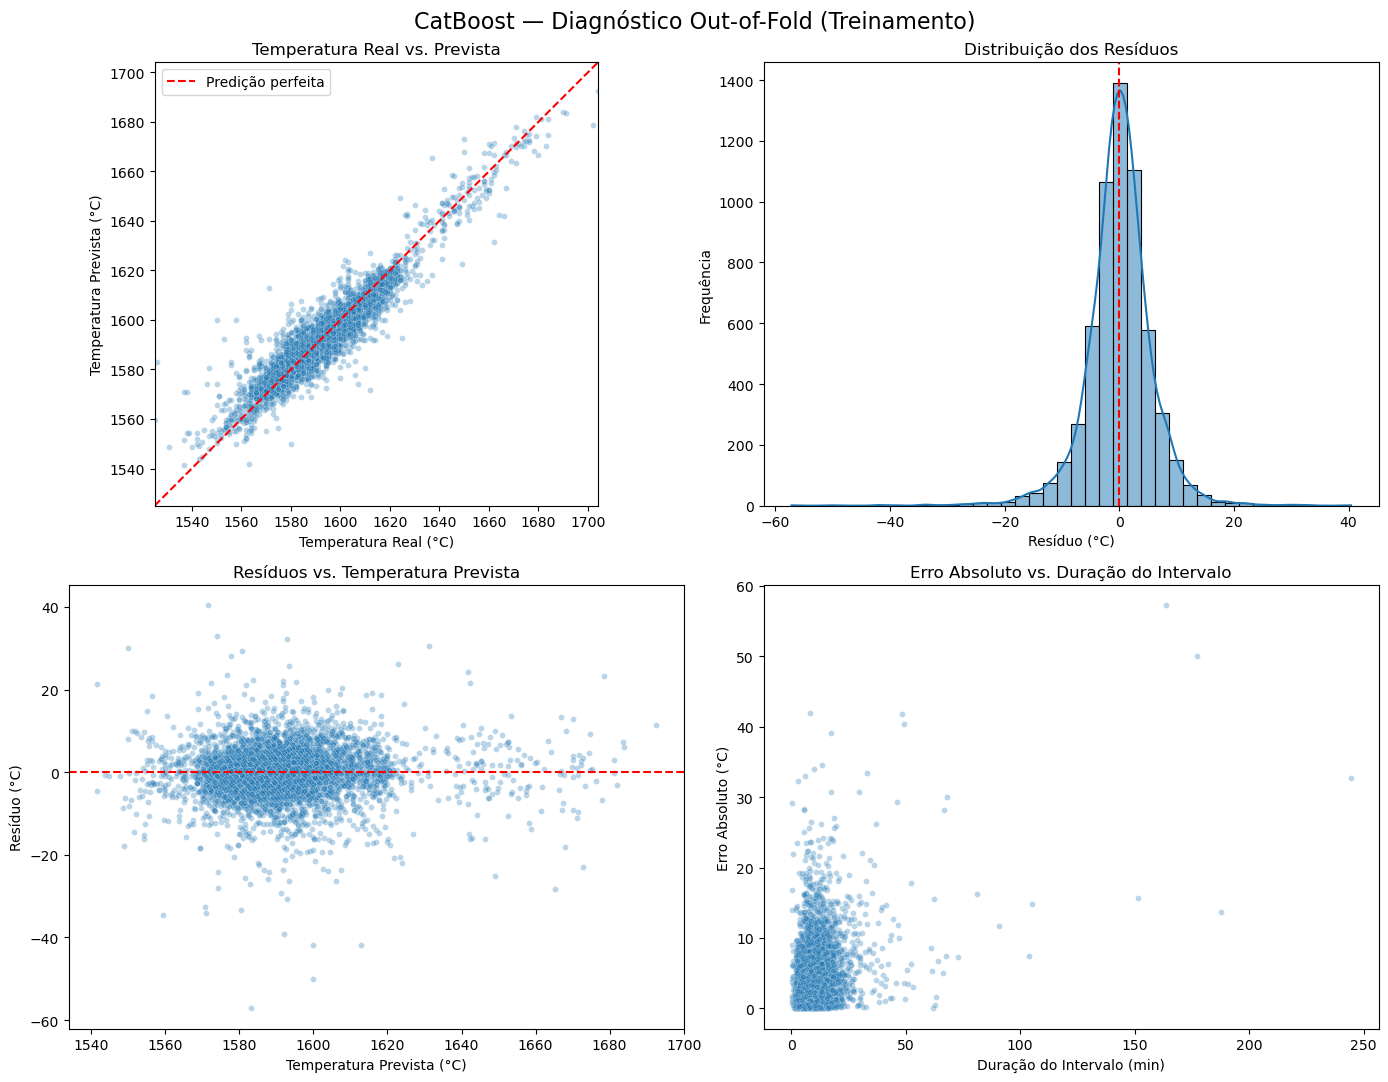

In [94]:
plot_model_diagnostics(
    cv_diagnostics,
    'CatBoost — Diagnóstico Out-of-Fold (Treinamento)'
)

Como podemos observar, o modelo CatBoost tem uma boa performance para o nosso problema. A distribuição de Temperaturas Reais vs Temperaturas Previstas mostra que a grande maioria das previsões está dentro do esperado e se adequa a nossa aplicação do modelo como Sensor Virtual de referência. Não é possível chegarmos a conclusões sobre a aplicação real sem entendermos a relação de temperatura com decisões operacionais de cada Lote de Refino Secundário, o que iria requerer mais informações e dados do que temos em mãos. Esse modelo poderia ser expandido com dados que não foram utilizados e mais informações sobre os dados. Por exemplo, se tivéssemos os dados temporais da purga de gás e as unidades de medida de active_power e reactive_power, poderíamos fazer uso dos dados de purga de gás e também usar active_power e reactive_power de maneira diferente. Embora isso não garanta um modelo melhor, essas informações poderiam permitir a criação de características mais representativas do processo e, potencialmente, melhorar o desempenho preditivo. Dessa forma, não posso afirmar que o desempenho do modelo seja operacionalmente adequado sem conhecer as tolerâncias de temperatura de cada processo. Entretanto, considero os resultados satisfatórios para uma primeira versão experimental de um sensor virtual, especialmente considerando as limitações dos dados disponíveis.

Ainda assim, precisamos considerar o gráfico de Erro Absolutio vs Duração de Intervalo. O gráfico sugere a possibilidade de erros maiores em intervalos mais longos. Entretanto, como a distribuição de durações está concentrada principalmente abaixo de 30 minutos, temos menos observações de intervalos longos, o que limita nossa capacidade de avaliar o desempenho nessas condições. 

A distribuição dos resíduos está concentrada próxima de 0°C, com dispersão relativamente pequena, indicando que o modelo geralmente produz previsões próximas das temperaturas observadas, embora ainda apresente erros elevados em algumas observações.

Isso não significa que o modelo seja perfeito ou não possa melhorar, mas sim que nosso treinamento foi efetivo dentro das limitações de dados impostas pelos conjuntos de dados utilizados.

In [95]:
absolute_errors = cv_diagnostics['absolute_error']

for threshold in [5, 10, 18, 20]:
    percentage = (absolute_errors <= threshold).mean() * 100
    print(f"Erros até {threshold}°C: {percentage:.2f}%")

Erros até 5°C: 72.34%
Erros até 10°C: 92.58%
Erros até 18°C: 98.62%
Erros até 20°C: 99.04%


Aqui podemos ver que 98.62% dos erros ficaram em até 18C, com 99.04% até 20C e 92.58% ficaram em até 10C. Esses resultados corroboram nossa conclusão de que a performance do modelo é excelente mas ainda existem limitações a serem avaliadas operacionalmente antes de aplicar o modelo abertamente em um uso real.

## Comparando Intervalos com Ciclos de Aquecimento e Intervalos sem Ciclos de Aquecimento

In [96]:
error_by_type = (
    cv_diagnostics
    .groupby('interval_type')['absolute_error']
    .agg(
        count='count',
        MAE='mean',
        median_absolute_error='median'
    )
)

display(error_by_type)

,count,MAE,median_absolute_error
interval_type,,,
Com aquecimento,5643,3.965574,2.772253
Somente materiais,297,5.492954,4.055465


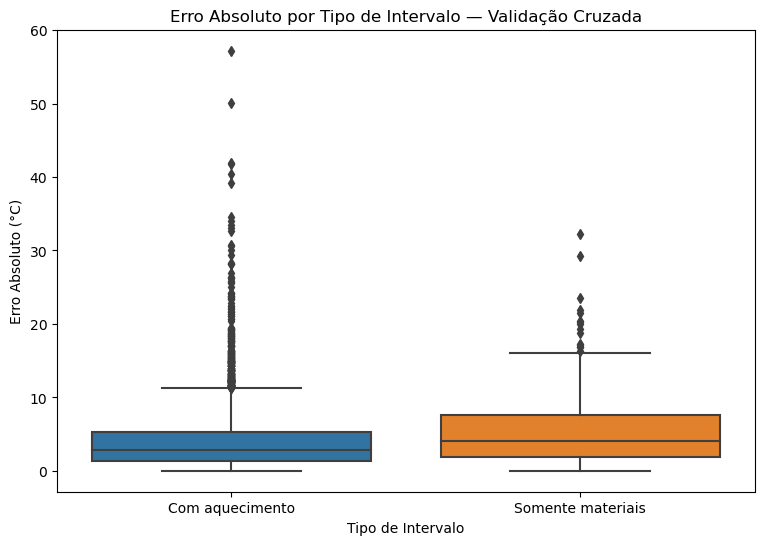

In [97]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=cv_diagnostics,
    x='interval_type',
    y='absolute_error',
    ax=ax
)

ax.set(
    title='Erro Absoluto por Tipo de Intervalo — Validação Cruzada',
    xlabel='Tipo de Intervalo',
    ylabel='Erro Absoluto (°C)'
)

plt.show()

Podemos comparar os erros absolutos dos intervalos que não tem ciclos de aquecimento com aqueles que tem ciclos de aquecimento. Essa comparação mostra o impacto das previsões para esses casos.

A distribuição dos Erros Absolutos para os Ciclos sem aquecimentos mas com adição de materiais é mais dispersa, contando com MAE de 5.49 e com uma diferença entre quartis maior. Já os Erros absolutos para os intervalos com ciclos de aquecimento tem MAE menor, ficando em 3.97 e com uma maiora concentração dos erros em volta desses dados. A maioria dos erros não passou muito de 10C para os ciclos com aquecimento, demostrando que a possível melhor aplicação do modelo seja justamente para intervalos que tem ciclos de aquecimento.

Para intervalos sem ciclos de aquecimento, seria importante avaliar se o desempenho do sensor virtual atende às tolerâncias operacionais da Steelproof. Caso os erros observados sejam superiores aos limites aceitáveis, medições diretas de temperatura poderiam ser priorizadas nessas situações.

## Maiores Erros

In [98]:
largest_errors = (
    cv_diagnostics
    .sort_values('absolute_error', ascending=False)
    .head(20)
)

display(largest_errors)

,,actual,predicted,persistence,temp_1,interval_minutes,heating_cycle_count,residual,absolute_error,persistence_absolute_error,interval_type
key,interval_no,,,,,,,,,,
1689,6,1526.0,1583.192298,1608.0,1608.0,163.516667,1,-57.192298,57.192298,82.0,Com aquecimento
801,3,1550.0,1600.028886,1646.0,1646.0,177.216667,1,-50.028886,50.028886,96.0,Com aquecimento
1044,2,1558.0,1599.872333,1587.0,1587.0,8.033333,1,-41.872333,41.872333,29.0,Com aquecimento
390,2,1571.0,1612.810078,1613.0,1613.0,48.250000,2,-41.810078,41.810078,42.0,Com aquecimento
686,2,1612.0,1571.616107,1561.0,1561.0,49.150000,4,40.383893,40.383893,51.0,Com aquecimento
660,3,1553.0,1592.125620,1596.0,1596.0,17.566667,1,-39.125620,39.125620,43.0,Com aquecimento
1503,1,1525.0,1559.493480,1525.0,1525.0,13.533333,2,-34.493480,34.493480,0.0,Com aquecimento
953,1,1537.0,1571.009908,1537.0,1537.0,10.083333,2,-34.009908,34.009908,0.0,Com aquecimento
1516,2,1547.0,1580.450995,1591.0,1591.0,33.300000,2,-33.450995,33.450995,44.0,Com aquecimento


A presença de erros absolutos elevados em algumas observações demonstra que, apesar do bom desempenho médio, o modelo ainda apresenta limitações importantes. Esses casos precisam ser considerados em uma eventual implementação real, especialmente quando as tolerâncias de temperatura forem pequenas. Tal decisão necessita de maiores informações sobre as limitações operacionais e metalúrgicas do problema de negócios.

## Análise da Importância Relativa das Variáveis

In [99]:
# Importância das características — CatBoost

catboost_estimator = best_model.named_steps['model']

feature_importance = pd.Series(
    catboost_estimator.get_feature_importance(),
    index=features_train.columns,
    name='importance'
).sort_values(ascending=False)

display(feature_importance.head(20))

temp_1                    64.408199
total_heating_duration     6.048022
active_power_mean          5.556015
interval_duration          4.620255
t1_to_first_heating        4.237202
heating_cycle_count        1.875297
reactive_power_mean        1.824146
bulk_14                    1.743422
bulk_14_time_to_t2         1.652152
bulk_15                    1.572551
wire_1_time_to_t2          1.455633
last_heating_to_t2         1.143830
wire_1                     1.119986
bulk_15_time_to_t2         0.870459
bulk_12                    0.699960
bulk_12_time_to_t2         0.525628
wire_2                     0.219377
bulk_3                     0.085897
bulk_4_time_to_t2          0.069810
wire_2_time_to_t2          0.042004
Name: importance, dtype: float64

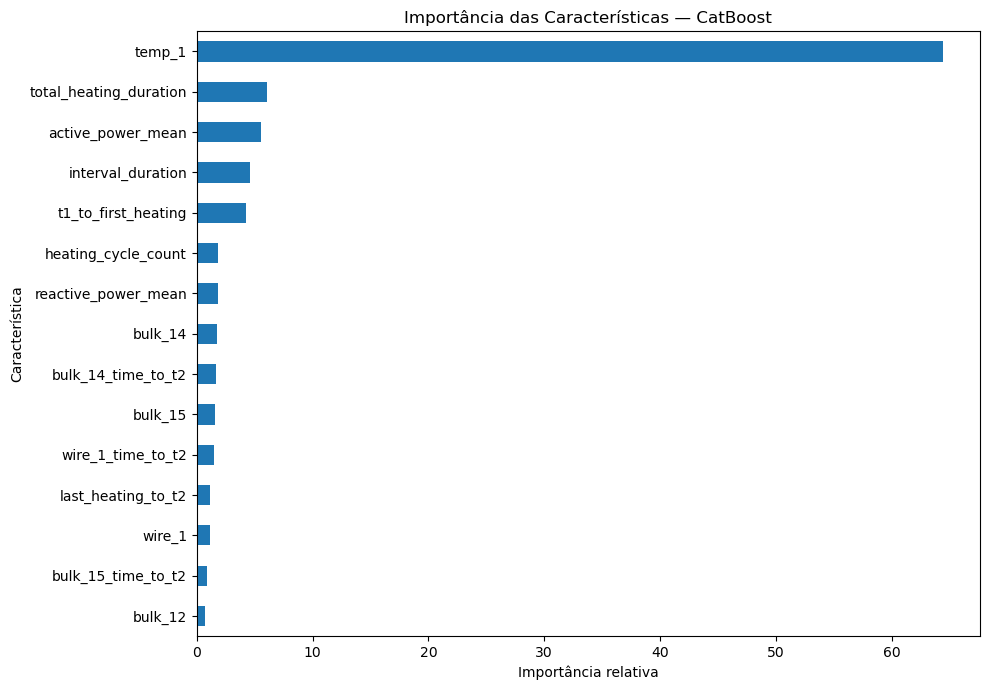

In [100]:
fig, ax = plt.subplots(figsize=(10, 7))

feature_importance.head(15).sort_values().plot(
    kind='barh',
    ax=ax
)

ax.set(
    title='Importância das Características — CatBoost',
    xlabel='Importância relativa',
    ylabel='Característica'
)

plt.tight_layout()
plt.show()


Ao analisar a importância relativa das variáveis, podemos ver que de longe, a variável mais importante é temp_1 que é a temperatura inicial do Intervalo. É esperado que a temperatura anterior tenha grande relevância preditiva, pois representa o estado térmico mais recente conhecido do aço. A temperatura posterior dependerá das operações realizadas durante o intervalo, incluindo aquecimento, adições de materiais e outros processos que podem influenciar a evolução térmica.

Isso não significa que as outras variáveis não tem importância, mas tem impacto menor na nossa predição. As outras variáveis com importância significativa são total_heating_duration (a duração total de aquecimento durante o intervalo), active_power_mean (a média da potência real dos ciclos do intervalo), interval_duration (a duração total do intervalo) e t1_to_first_heating (o tempo entre a primeira medição de temperatura e o início do primeiro ciclo de aquecimento). No geral, as variáveis mais importantes são aquelas que tem ligação direta com as temperaturas e mudanças de temperatura, como interval_duration e total_heating_duration.

É interessante notar que active_power_mean também tem uma importância grande comparado com outras variáveis. Isso corrobora a importância de recebermos mais informações sobre esse tip ode dados em um caso real. Seria interessante saber as unidades de medida usadas para active_power mas também a natureza dessa coluna, se ela é uma soma ou uma média da potência real de um ciclo de aquecimento por exemplo. Fazer melhor uso dessa variável tem o potencial de significar uma melhora real no nosso modelo.

Algumas outras variáveis também apareceram dentre as 15 com maior importância relativa, a maioria também temporais como bulk_15_time_to_t2, e last_heating_to_t2. SOmente alguns volumes de materiais apareceram nas 15 variáveis mais importantes e especificamente bulk_14, bulk_15 e bulk_12 são os materiais que são adicionados com maior frequência nos Lotes, como vimos no nosso caderno de planejamento na sessão "Dados sobre o Fornecimento de Materiais a Granel (data_bulk_en)": "Os materiais **bulk_12**, **bulk_14** e **bulk_15** são adicionados na maioria dos Lotes, com frequência de adição de 78%, 90% e 72% dos Lotes respectivamente".

É importante pontuar que a importância definida por CatBoost é um resumo sobre o comportamento do modelo e não um reflexo de relações físicas entre as variáveis.

## Testando o Melhor Modelo nos Dados de Teste

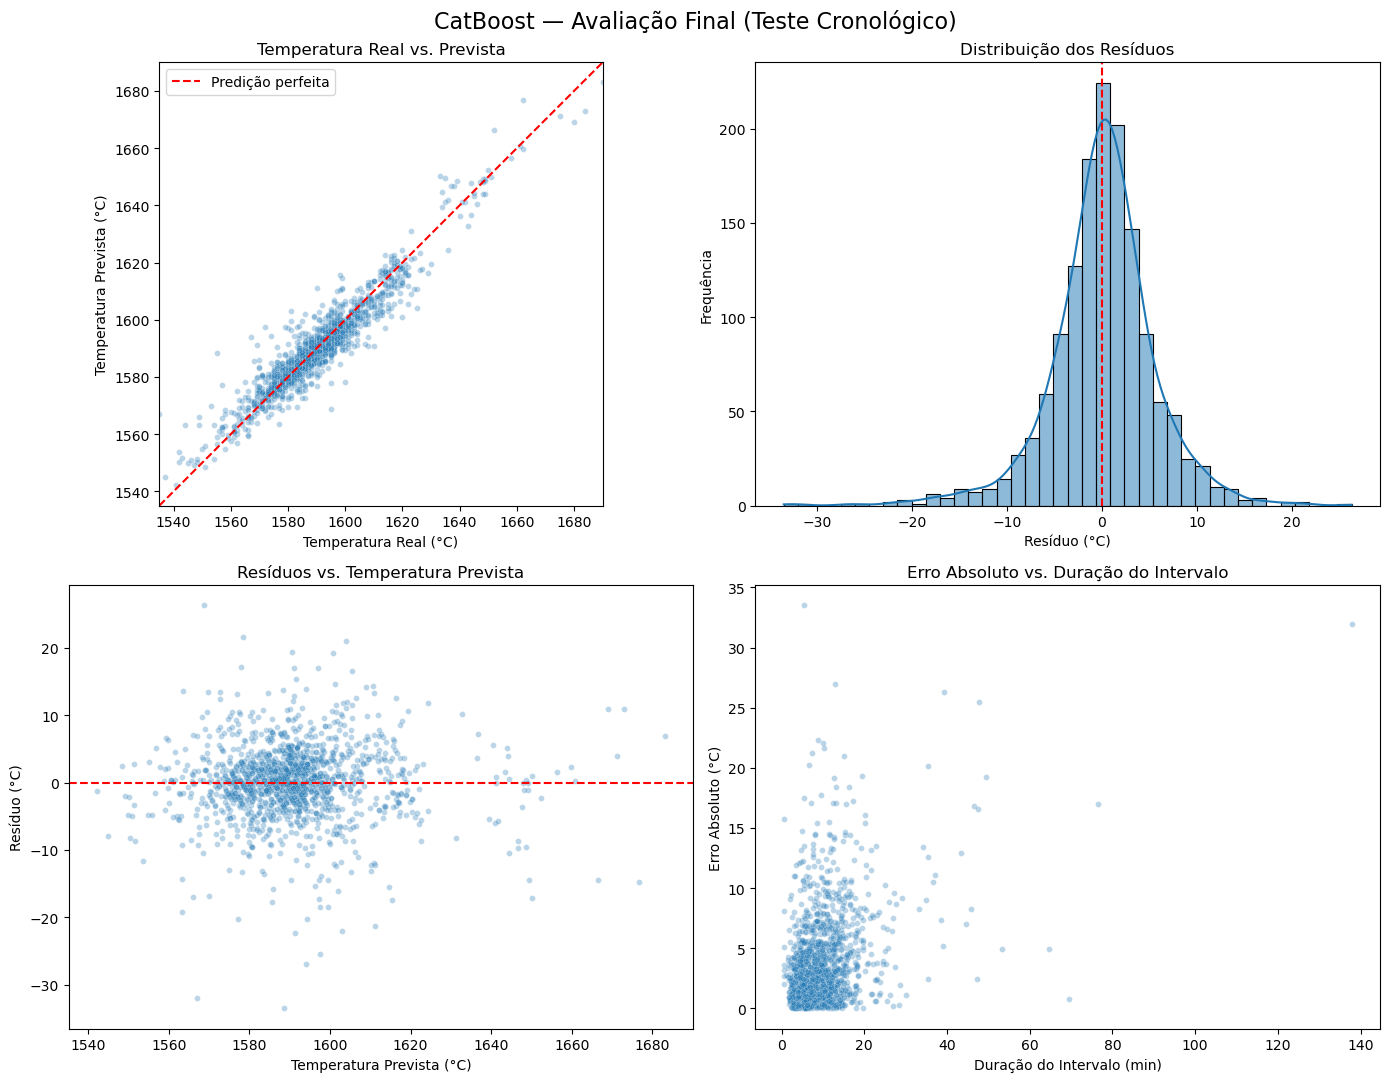

,model,MAE,RMSE,R2,Iem
0,CatBoost,3.928296,5.585677,0.895133,0.592551
1,Persistence,9.641205,13.232861,0.411433,0.000000


In [101]:
# Predições no conjunto de teste
test_predictions = best_model.predict(features_test)

test_diagnostics = build_diagnostics(
    features_test,
    target_test,
    test_predictions
)

test_diagnostics.to_csv('../../results/test_diagnostics.csv',index=False)

plot_model_diagnostics(
    test_diagnostics,
    'CatBoost — Avaliação Final (Teste Cronológico)'
)

# Predições do modelo de persistência
persistence_test_predictions = model_persistence.predict(features_test)

# KPIs do modelo selecionado
final_metrics = return_kpi(
    target_test,
    test_predictions,
    persistence_test_predictions
)

persistence_test_metrics = return_kpi(
    target_test,
    persistence_test_predictions,
    persistence_test_predictions
)

final_results = pd.DataFrame([
    {'model': 'CatBoost', **final_metrics},
    {'model': 'Persistence', **persistence_test_metrics}
])



display(final_results)

In [102]:
test_error_by_type = (
    test_diagnostics
    .groupby('interval_type')['absolute_error']
    .agg(
        count='count',
        MAE='mean',
        median_absolute_error='median'
    )
)

display(test_error_by_type)

,count,MAE,median_absolute_error
interval_type,,,
Com aquecimento,1360,3.882868,2.771131
Somente materiais,67,4.850414,3.623476


## Conclusão para o Problema de Negócios



O objetivo deste projeto foi desenvolver um modelo de regressão capaz de prever a temperatura do aço durante o processo de refino secundário, funcionando como um sensor virtual a partir de informações sobre medições de temperatura anteriores, ciclos de aquecimento e adições de materiais.

Após o processamento e a seleção dos dados, obtivemos 7.368 intervalos de medição de temperatura para treinamento e teste. Os dados foram divididos cronologicamente por lote, preservando a independência entre os conjuntos de treinamento e teste, mas também a cronologia dos Lotes.

Foram avaliados os modelos de Persistência, DummyRegressor, Ridge, RandomForest, LightGBM e CatBoost. Os modelos de regressão foram comparados por validação cruzada com GroupKFold, e seus hiperparâmetros foram posteriormente otimizados utilizando RandomizedSearchCV.

**O melhor modelo identificado foi CatBoost**, com MAE de $4,042^oC$ durante a validação cruzada após otimização de hiperparâmetros. No conjunto de teste, o modelo obteve MAE de 3,927°C, RMSE de 5,584°C e R² de 0,895, além de uma redução de aproximadamente 59,25% no MAE em comparação com o modelo de Persistência que era a nossa baseline. Os limiares de desempenho foram definidos em 10C para MAE, 15C para RMSE e 20% de redução no MAE em comparação com o modelo de Persistência. Dessa forma, todos os limiares de desempenho definidos para o projeto foram atingidos.

Os resultados demonstram que as características operacionais utilizadas contêm informações relevantes para estimar a temperatura do aço e que o modelo oferece uma melhoria significativa em relação à utilização exclusiva da última temperatura medida.

Entretanto, a análise dos resíduos mostrou que ainda existem observações com erros consideravelmente superiores à média. O modelo também apresentou desempenho inferior nos intervalos sem aquecimento, mas com adição de materiais. Essas limitações devem ser consideradas em uma eventual aplicação operacional.

Além disso, os conjuntos de dados não incluem informações completas sobre a composição química do aço, as condições de purga de gás ao longo do tempo e as tolerâncias operacionais específicas de cada produto. Portanto, não é possível estabelecer, apenas com os resultados deste estudo, que os erros do modelo sejam aceitáveis para todas as situações do processo produtivo.

Outra limitação importante é que o modelo foi treinado a partir de intervalos delimitados por medições reais de temperatura. Portanto, embora sua aplicação como sensor virtual seja promissora, ainda não demonstramos que o modelo seja capaz de estimar temperaturas com a mesma precisão em instantes arbitrários durante o processo. Seria necessário validar seu desempenho em condições reais de utilização, com informações operacionais disponíveis até o instante da previsão e medições de referência para comparação.

**Recomenda-se considerar o modelo como candidato a uma ferramenta de apoio ao monitoramento de temperatura**, inicialmente sujeita à validação pelos especialistas e operadores das plantas de processo e qualidade da Steelproof. Uma futura implementação deveria avaliar o desempenho do modelo em novos lotes, definir limites operacionais de erro e estabelecer situações em que medições diretas continuariam sendo obrigatórias. Uma futura implementação também se beneficiaria de mais informações sobre os dados de purga de gás e uso de energia elétrica.

O projeto demonstrou a viabilidade preditiva de um sensor virtual com base nos registros históricos disponíveis, mas a adoção operacional dependeria de validações adicionais com dados de produção e requisitos específicos da empresa.

Como discutido anteriormente, as limitações dos dados impossibilitam uma análise concreta do impacto no consumo de energia elétrica ao usar o modelo, mas futuras versões do modelo juntamente de mais dados sobre a energia elétrica poderiam chegar a conclusões úteis e ricas sobre essa relação.

Uma última possibilidade seria reincluir os intervalos sem ciclos de aquecimento ou adições de materiais uma vez que essas observações poderiam contribuir para o modelo aprender a relação do esfriamento passivo dos Lotes de aço.

# REFERÊNCIAS

- Brown, John - "Foseco Ferrous Foundryman's Handbook", Butterworth Heinemann, Woburn, MA 2000